# Projeto Final - Fundamentos de Machine Learning

**Integrantes do grupo:** Charlene, Cinthia, Cristiane e Douglas

**Base de dados:** `estudantes_desempenho.CSV`, versão traduzida para o português do *Student Performance Dataset* (disciplina de Língua Portuguesa, alunos do ensino secundário de duas escolas de Portugal: Gabriel Pereira - GP e Mousinho da Silveira - MS).

**Fonte original:** UCI Machine Learning Repository - https://archive.ics.uci.edu/dataset/320/student+performance (licença CC BY 4.0). Os dados foram coletados por P. Cortez e A. Silva (2008) a partir de boletins escolares e questionários respondidos pelos alunos.

**Tamanho:** 649 linhas (cada linha é um estudante) e 33 colunas.

---

# Etapa 1: Descrição do Problema

> **Enunciado da Especificação (Etapa 1):** *"1. Descrição do problema: o que vocês querem prever, classificar ou agrupar, e por que isso importa. Que decisão o modelo apoiaria?"*

### 1.1 O que queremos prever, classificar e agrupar

O tema do projeto é o desempenho escolar. Usamos a mesma base em três tarefas vistas na disciplina:

1. **Regressão:** prever a `Nota_Final` do aluno, que vai de 0 a 20 pontos.
2. **Classificação:** prever o `Risco_Reprovacao`. No sistema português a aprovação exige nota final maior ou igual a 10, então definimos `1` = reprovado (`Nota_Final < 10`) e `0` = aprovado (`Nota_Final >= 10`). Os reprovados são 100 dos 649 alunos (15,41%).
3. **Agrupamento (K-Means + PCA):** separar os alunos em perfis a partir de variáveis familiares e de comportamento, sem usar as notas, e depois verificar quais perfis concentram mais reprovação.

### 1.2 Por que isso importa e que decisão o modelo apoiaria

Quando a escola só descobre quem vai reprovar depois da nota final, não há mais o que fazer. A ideia é apoiar a coordenação pedagógica a decidir **quais alunos devem receber reforço, tutoria ou acompanhamento com a família**, já que esses recursos são limitados.

Pensamos em dois momentos de uso:

* **Cenário A - início do ano letivo:** a escola tem apenas o questionário do aluno e o histórico (por exemplo, reprovações anteriores). Não há notas do ano nem faltas do ano.
* **Cenário B - fim do 2º período:** a escola já tem as notas do 1º e do 2º período e as faltas registradas, e quer saber quem ainda corre risco antes da avaliação final.

### 1.3 Dicionário de dados

A base não traz legenda própria. Os códigos numéricos abaixo vêm da documentação original do UCI (Cortez e Silva, 2008) e foram traduzidos por nós. Nas escalas de 1 a 5, a documentação define apenas os extremos; os valores 2, 3 e 4 são níveis intermediários.

| Nº | Coluna | O que representa | Tipo | Valores / códigos |
|---|---|---|---|---|
| 1 | `Escola` | Escola do aluno | Categórica binária | GP = Gabriel Pereira; MS = Mousinho da Silveira |
| 2 | `Sexo` | Sexo do aluno | Categórica binária | Feminino; Masculino |
| 3 | `Idade` | Idade em anos | Numérica | 15 a 22 |
| 4 | `Tipo_de_Endereco` | Onde o aluno mora | Categórica binária | Urbano; Rural |
| 5 | `Tamanho_da_Familia` | Número de pessoas na família | Categórica binária | Ate 3 (até 3 pessoas); Mais de 3 |
| 6 | `Situacao_dos_Pais` | Se os pais moram juntos | Categórica binária | Juntos; Separados |
| 7 | `Escolaridade_da_Mae` | Escolaridade da mãe | Ordinal | 0 = nenhuma; 1 = ensino primário (até o 4º ano); 2 = do 5º ao 9º ano; 3 = ensino secundário (equivale ao ensino médio); 4 = ensino superior |
| 8 | `Escolaridade_do_Pai` | Escolaridade do pai | Ordinal | mesma escala da mãe (0 a 4) |
| 9 | `Ocupacao_da_Mae` | Profissão da mãe | Categórica nominal | Professor(a); Saude; Servicos (serviços públicos, como administrativo ou polícia); Em casa; Outro |
| 10 | `Ocupacao_do_Pai` | Profissão do pai | Categórica nominal | mesmas categorias da mãe |
| 11 | `Motivo_da_Escolha_da_Escola` | Por que escolheu a escola | Categórica nominal | Proximidade de casa; Reputacao da escola; Preferencia pelo curso; Outro |
| 12 | `Responsavel` | Responsável pelo aluno | Categórica nominal | Mae; Pai; Outro |
| 13 | `Tempo_de_Deslocamento` | Tempo de casa até a escola | Ordinal | 1 = menos de 15 min; 2 = 15 a 30 min; 3 = 30 min a 1 hora; 4 = mais de 1 hora |
| 14 | `Tempo_de_Estudo_Semanal` | Horas de estudo por semana | Ordinal | 1 = menos de 2 h; 2 = 2 a 5 h; 3 = 5 a 10 h; 4 = mais de 10 h |
| 15 | `Reprovacoes_Anteriores` | Reprovações em anos anteriores | Numérica discreta | 0 = nenhuma; 1; 2; 3 = três ou mais |
| 16 | `Apoio_Educacional_da_Escola` | Recebe apoio extra da escola | Binária | Sim; Não |
| 17 | `Apoio_Educacional_Familiar` | Recebe apoio da família nos estudos | Binária | Sim; Não |
| 18 | `Aulas_Particulares_Pagas` | Faz aulas particulares pagas da disciplina | Binária | Sim; Não |
| 19 | `Atividades_Extracurriculares` | Faz atividades extracurriculares | Binária | Sim; Não |
| 20 | `Frequentou_Educacao_Infantil` | Frequentou creche/pré-escola | Binária | Sim; Não |
| 21 | `Pretende_Cursar_Ensino_Superior` | Quer fazer faculdade | Binária | Sim; Não |
| 22 | `Acesso_a_Internet_em_Casa` | Tem internet em casa | Binária | Sim; Não |
| 23 | `Relacionamento_Amoroso` | Está namorando | Binária | Sim; Não |
| 24 | `Qualidade_das_Relacoes_Familiares` | Como avalia a relação com a família | Ordinal | 1 = muito ruim ... 5 = excelente |
| 25 | `Tempo_Livre_Apos_a_Escola` | Tempo livre depois da aula | Ordinal | 1 = muito pouco ... 5 = muito |
| 26 | `Frequencia_de_Saidas_com_Amigos` | Quanto sai com os amigos | Ordinal | 1 = muito pouco ... 5 = muito |
| 27 | `Consumo_de_Alcool_em_Dias_Uteis` | Consumo de álcool de segunda a sexta | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 28 | `Consumo_de_Alcool_no_Fim_de_Semana` | Consumo de álcool no fim de semana | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 29 | `Estado_de_Saude_Atual` | Como avalia a própria saúde | Ordinal | 1 = muito ruim ... 5 = muito bom |
| 30 | `Numero_de_Faltas` | Faltas no ano letivo | Numérica | 0 a 93 na documentação (nesta base vai até 32) |
| 31 | `Nota_1o_Periodo` | Nota do 1º período | Numérica | 0 a 20 |
| 32 | `Nota_2o_Periodo` | Nota do 2º período | Numérica | 0 a 20 |
| 33 | `Nota_Final` | Nota final do ano (3º período) | Numérica - **alvo da regressão** | 0 a 20 (aprovado com 10 ou mais) |

Colunas que nós criamos durante o projeto:

| Coluna criada | Significado | Códigos |
|---|---|---|
| `Situacao_Final` | Situação do aluno, usada só na análise exploratória | Aprovado (nota final >= 10); Reprovado (nota final < 10) |
| `Risco_Reprovacao` | **Alvo da classificação** | 1 = reprovado; 0 = aprovado |
| `Cluster` | Perfil encontrado pelo K-Means | número do grupo (0, 1, 2...), sem ordem de importância; o significado de cada grupo é descrito na Etapa 5 |

---

# Etapa 2: Pré-processamento e Análise Exploratória dos Dados (EDA)

> **Enunciado da Especificação (Etapa 2):** *"2. Pré-processamento e análise exploratória: tratamento de valores ausentes, normalização ou transformação, codificação de variáveis categóricas e uma EDA que justifique essas escolhas."*

Nesta etapa conferimos a estrutura e a qualidade da base (ausentes, duplicados, tipos, valores fora da escala) e olhamos as relações entre as variáveis e a nota final. Aqui nada é ajustado nos dados: a codificação e a padronização são definidas no fim da etapa, mas só são aplicadas depois da divisão treino/teste (Etapas 3 e 4), dentro de um `Pipeline`.

## 2.1 Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SEMENTE = 42  # mesma semente em todo o notebook para os resultados se repetirem

## 2.2 Carregamento do CSV

O arquivo usa ponto e vírgula como separador e acentuação em `latin-1`. Para rodar no Colab, o CSV precisa estar na mesma pasta do notebook (ou ser enviado pelo menu de arquivos).

In [2]:
arquivo = "estudantes_desempenho.CSV"
df = pd.read_csv(arquivo, sep=";", encoding="latin-1")
df.head()

,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
0,GP,Feminino,18,Urbano,Mais_de_3,Separados,4,4,Em_casa,Professor(a),Preferencia_pelo_curso,Mae,2,2,0,Sim,Não,Não,Não,Sim,Sim,Não,Não,4,3,4,1,1,3,4,0,11,11
1,GP,Feminino,17,Urbano,Mais_de_3,Juntos,1,1,Em_casa,Outro,Preferencia_pelo_curso,Pai,1,2,0,Não,Sim,Não,Não,Não,Sim,Sim,Não,5,3,3,1,1,3,2,9,11,11
2,GP,Feminino,15,Urbano,Ate_3,Juntos,1,1,Em_casa,Outro,Outro,Mae,1,2,0,Sim,Não,Não,Não,Sim,Sim,Sim,Não,4,3,2,2,3,3,6,12,13,12
3,GP,Feminino,15,Urbano,Mais_de_3,Juntos,4,2,Saude,Servicos,Proximidade_de_casa,Mae,1,3,0,Não,Sim,Não,Sim,Sim,Sim,Sim,Sim,3,2,2,1,1,5,0,14,14,14
4,GP,Feminino,16,Urbano,Mais_de_3,Juntos,3,3,Outro,Outro,Proximidade_de_casa,Pai,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,4,3,2,1,2,5,0,11,13,13


## 2.3 Dimensão da base

In [3]:
print(f"Estudantes (linhas): {df.shape[0]}")
print(f"Variáveis (colunas): {df.shape[1]}")

Estudantes (linhas): 649
Variáveis (colunas): 33


## 2.4 Tipos das variáveis

Várias colunas numéricas são, na verdade, códigos de escala (ver o dicionário na seção 1.3). Por exemplo, `Tempo_de_Estudo_Semanal = 3` não quer dizer 3 horas, e sim "de 5 a 10 horas".

In [4]:
df.columns = df.columns.str.strip()
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(exclude="number").columns.tolist()

df.info()
print("\nNuméricas:", len(colunas_numericas), "| Categóricas:", len(colunas_categoricas))

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Escola                              649 non-null    str  
 1   Sexo                                649 non-null    str  
 2   Idade                               649 non-null    int64
 3   Tipo_de_Endereco                    649 non-null    str  
 4   Tamanho_da_Familia                  649 non-null    str  
 5   Situacao_dos_Pais                   649 non-null    str  
 6   Escolaridade_da_Mae                 649 non-null    int64
 7   Escolaridade_do_Pai                 649 non-null    int64
 8   Ocupacao_da_Mae                     649 non-null    str  
 9   Ocupacao_do_Pai                     649 non-null    str  
 10  Motivo_da_Escolha_da_Escola         649 non-null    str  
 11  Responsavel                         649 non-null    str  
 12  Tempo_de_Deslocamen

## 2.5 Limpeza dos textos

Tiramos espaços nas pontas e trocamos `_` por espaço nos valores de texto (ex.: `Mais_de_3` vira `Mais de 3`), só para facilitar a leitura das tabelas e gráficos.

In [5]:
for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip().str.replace("_", " ", regex=False)

## 2.6 Valores ausentes

Procuramos tanto nulos de verdade quanto marcadores escritos como texto (`"NA"`, `"?"`, `"-"` etc.), que o pandas não reconhece como ausentes.

In [6]:
marcadores_texto = ["", " ", "NA", "N/A", "null", "Null", "?", "-"]

ausentes = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Marcadores de texto": df[colunas_categoricas].isin(marcadores_texto).sum().reindex(df.columns, fill_value=0),
})
print("Total de nulos:", int(ausentes["Nulos"].sum()))
print("Total de marcadores de texto:", int(ausentes["Marcadores de texto"].sum()))
ausentes[ausentes.sum(axis=1) > 0]

Total de nulos: 0
Total de marcadores de texto: 0


,Nulos,Marcadores de texto


A base não tem nenhum valor ausente, nem disfarçado de texto. Por isso não foi preciso imputar nem remover linhas. Mesmo assim, deixamos o tratamento preparado no pipeline (`handle_unknown="ignore"` no codificador) para categorias novas que apareçam no teste.

## 2.7 Duplicidades

Como não há identificador de aluno, conferimos se existem linhas idênticas.

In [7]:
print("Linhas completamente duplicadas:", df.duplicated().sum())

Linhas completamente duplicadas: 0


## 2.8 Categorias

In [8]:
for coluna in colunas_categoricas:
    contagem = df[coluna].value_counts()
    print(f"{coluna}: " + " | ".join(f"{k} = {v}" for k, v in contagem.items()))

Escola: GP = 423 | MS = 226
Sexo: Feminino = 383 | Masculino = 266
Tipo_de_Endereco: Urbano = 452 | Rural = 197
Tamanho_da_Familia: Mais de 3 = 457 | Ate 3 = 192
Situacao_dos_Pais: Juntos = 569 | Separados = 80
Ocupacao_da_Mae: Outro = 258 | Servicos = 136 | Em casa = 135 | Professor(a) = 72 | Saude = 48
Ocupacao_do_Pai: Outro = 367 | Servicos = 181 | Em casa = 42 | Professor(a) = 36 | Saude = 23
Motivo_da_Escolha_da_Escola: Preferencia pelo curso = 285 | Proximidade de casa = 149 | Reputacao da escola = 143 | Outro = 72
Responsavel: Mae = 455 | Pai = 153 | Outro = 41
Apoio_Educacional_da_Escola: Não = 581 | Sim = 68
Apoio_Educacional_Familiar: Sim = 398 | Não = 251
Aulas_Particulares_Pagas: Não = 610 | Sim = 39
Atividades_Extracurriculares: Não = 334 | Sim = 315
Frequentou_Educacao_Infantil: Sim = 521 | Não = 128
Pretende_Cursar_Ensino_Superior: Sim = 580 | Não = 69
Acesso_a_Internet_em_Casa: Sim = 498 | Não = 151
Relacionamento_Amoroso: Não = 410 | Sim = 239


Treze variáveis de texto têm só duas categorias (sim/não, urbano/rural etc.) e quatro têm de três a cinco categorias (ocupações, motivo da escolha e responsável). Algumas são bem desequilibradas: só 39 alunos fazem aulas particulares pagas e só 68 recebem apoio extra da escola.

## 2.9 Estatísticas descritivas e leitura dos códigos

In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Escolaridade_da_Mae,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Escolaridade_do_Pai,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Qualidade_das_Relacoes_Familiares,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
Tempo_Livre_Apos_a_Escola,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
Frequencia_de_Saidas_com_Amigos,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Consumo_de_Alcool_em_Dias_Uteis,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Para ler as médias acima é preciso lembrar dos códigos. A tabela a seguir mostra, para cada variável codificada, o significado de cada número e quantos alunos estão em cada nível.

In [10]:
escala_1a5 = lambda baixo, alto: {1: f"1 - {baixo}", 2: "2", 3: "3", 4: "4", 5: f"5 - {alto}"}
escolaridade = {0: "Nenhuma", 1: "Primário (até 4º ano)", 2: "5º ao 9º ano",
                3: "Secundário (ensino médio)", 4: "Superior"}

dicionario_codigos = {
    "Escolaridade_da_Mae": escolaridade,
    "Escolaridade_do_Pai": escolaridade,
    "Tempo_de_Deslocamento": {1: "Menos de 15 min", 2: "15 a 30 min", 3: "30 min a 1 h", 4: "Mais de 1 h"},
    "Tempo_de_Estudo_Semanal": {1: "Menos de 2 h", 2: "2 a 5 h", 3: "5 a 10 h", 4: "Mais de 10 h"},
    "Reprovacoes_Anteriores": {0: "Nenhuma", 1: "1", 2: "2", 3: "3 ou mais"},
    "Qualidade_das_Relacoes_Familiares": escala_1a5("Muito ruim", "Excelente"),
    "Tempo_Livre_Apos_a_Escola": escala_1a5("Muito pouco", "Muito"),
    "Frequencia_de_Saidas_com_Amigos": escala_1a5("Muito pouco", "Muito"),
    "Consumo_de_Alcool_em_Dias_Uteis": escala_1a5("Muito baixo", "Muito alto"),
    "Consumo_de_Alcool_no_Fim_de_Semana": escala_1a5("Muito baixo", "Muito alto"),
    "Estado_de_Saude_Atual": escala_1a5("Muito ruim", "Muito bom"),
}

linhas = []
for coluna, mapa in dicionario_codigos.items():
    contagem = df[coluna].value_counts()
    for codigo, significado in mapa.items():
        linhas.append([coluna, codigo, significado, int(contagem.get(codigo, 0))])

tabela_codigos = pd.DataFrame(linhas, columns=["Variável", "Código", "Significado", "Alunos"])
tabela_codigos

,Variável,Código,Significado,Alunos
0,Escolaridade_da_Mae,0,Nenhuma,6
1,Escolaridade_da_Mae,1,Primário (até 4º ano),143
2,Escolaridade_da_Mae,2,5º ao 9º ano,186
3,Escolaridade_da_Mae,3,Secundário (ensino médio),139
4,Escolaridade_da_Mae,4,Superior,175
5,Escolaridade_do_Pai,0,Nenhuma,7
6,Escolaridade_do_Pai,1,Primário (até 4º ano),174
7,Escolaridade_do_Pai,2,5º ao 9º ano,209
8,Escolaridade_do_Pai,3,Secundário (ensino médio),131
9,Escolaridade_do_Pai,4,Superior,128


In [11]:
df.describe(exclude="number").T

,count,unique,top,freq
Escola,649,2,GP,423
Sexo,649,2,Feminino,383
Tipo_de_Endereco,649,2,Urbano,452
Tamanho_da_Familia,649,2,Mais de 3,457
Situacao_dos_Pais,649,2,Juntos,569
Ocupacao_da_Mae,649,5,Outro,258
Ocupacao_do_Pai,649,5,Outro,367
Motivo_da_Escolha_da_Escola,649,4,Preferencia pelo curso,285
Responsavel,649,3,Mae,455
Apoio_Educacional_da_Escola,649,2,Não,581


Alguns pontos que já aparecem nas estatísticas: a média de `Reprovacoes_Anteriores` é 0,22 porque a grande maioria nunca reprovou; `Tempo_de_Estudo_Semanal` tem média 1,93, ou seja, a maior parte estuda menos de 5 horas por semana (códigos 1 e 2); e `Numero_de_Faltas` tem média 3,66, mas máximo 32, o que indica uma cauda longa.

## 2.10 Verificação de valores fora da escala

Comparamos cada coluna com a faixa permitida pelo dicionário.

In [12]:
faixas = {
    "Idade": (15, 22), "Escolaridade_da_Mae": (0, 4), "Escolaridade_do_Pai": (0, 4),
    "Tempo_de_Deslocamento": (1, 4), "Tempo_de_Estudo_Semanal": (1, 4), "Reprovacoes_Anteriores": (0, 3),
    "Qualidade_das_Relacoes_Familiares": (1, 5), "Tempo_Livre_Apos_a_Escola": (1, 5),
    "Frequencia_de_Saidas_com_Amigos": (1, 5), "Consumo_de_Alcool_em_Dias_Uteis": (1, 5),
    "Consumo_de_Alcool_no_Fim_de_Semana": (1, 5), "Estado_de_Saude_Atual": (1, 5),
    "Numero_de_Faltas": (0, 93), "Nota_1o_Periodo": (0, 20), "Nota_2o_Periodo": (0, 20), "Nota_Final": (0, 20),
}
verificacao = pd.DataFrame(
    [[c, mn, mx, int(df[c].min()), int(df[c].max()), int(((df[c] < mn) | (df[c] > mx)).sum())]
     for c, (mn, mx) in faixas.items()],
    columns=["Variável", "Mín. permitido", "Máx. permitido", "Mín. na base", "Máx. na base", "Fora da faixa"],
)
verificacao

,Variável,Mín. permitido,Máx. permitido,Mín. na base,Máx. na base,Fora da faixa
0,Idade,15,22,15,22,0
1,Escolaridade_da_Mae,0,4,0,4,0
2,Escolaridade_do_Pai,0,4,0,4,0
3,Tempo_de_Deslocamento,1,4,1,4,0
4,Tempo_de_Estudo_Semanal,1,4,1,4,0
5,Reprovacoes_Anteriores,0,3,0,3,0
6,Qualidade_das_Relacoes_Familiares,1,5,1,5,0
7,Tempo_Livre_Apos_a_Escola,1,5,1,5,0
8,Frequencia_de_Saidas_com_Amigos,1,5,1,5,0
9,Consumo_de_Alcool_em_Dias_Uteis,1,5,1,5,0


Nenhum valor está fora da faixa da documentação.

## 2.11 Distribuição das notas

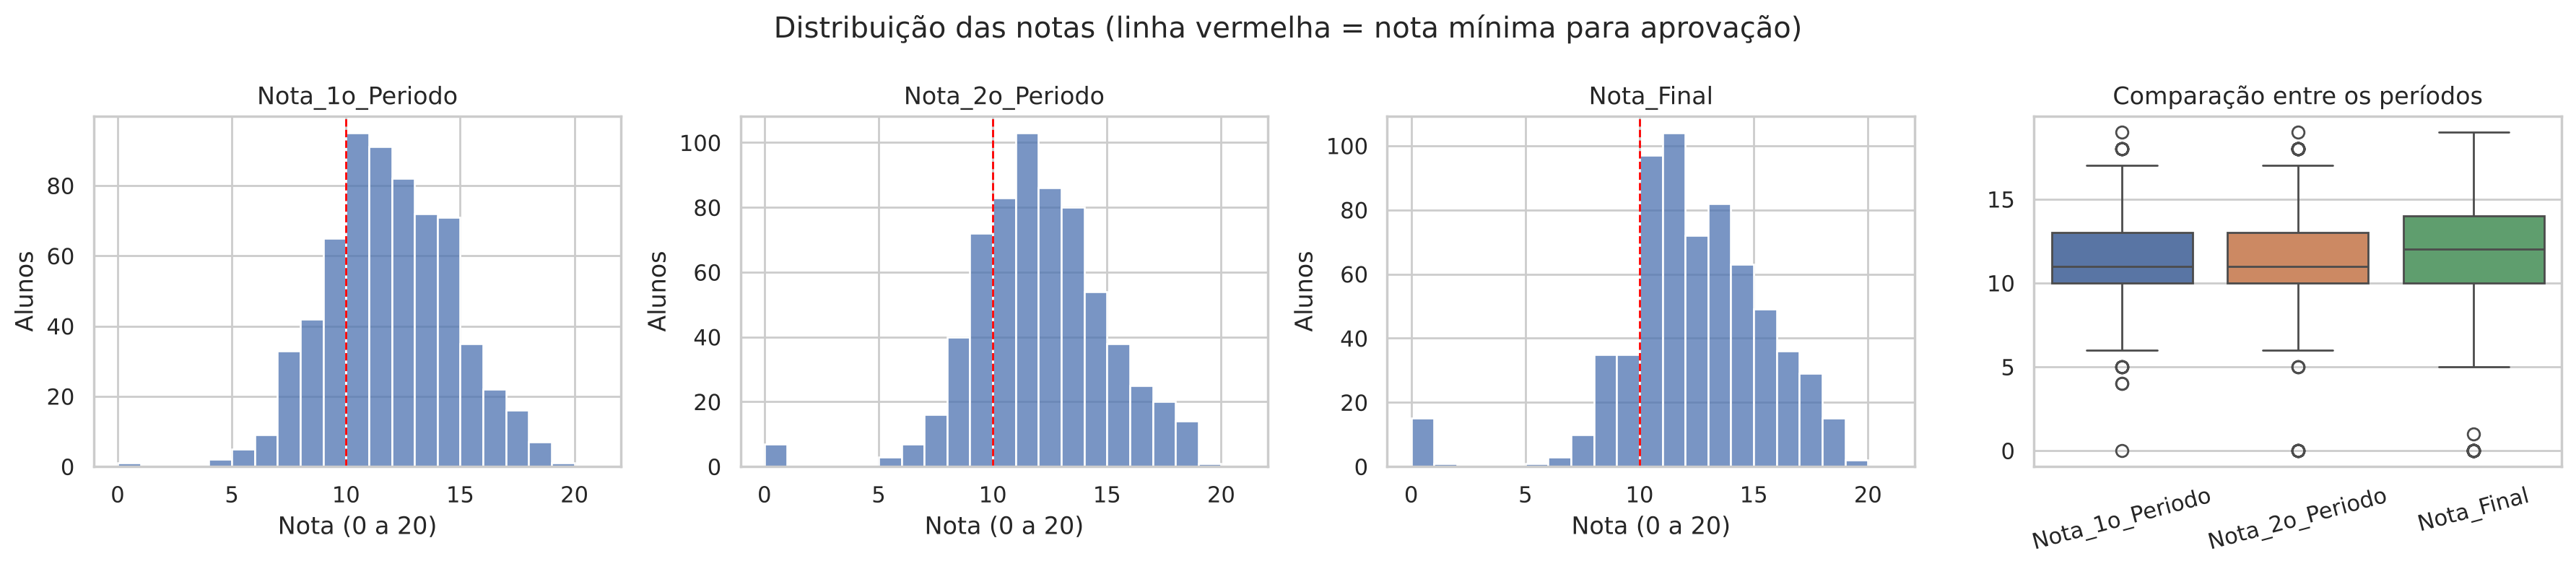

,count,mean,std,min,25%,50%,75%,max
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


In [13]:
colunas_notas = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, coluna in zip(axes[:3], colunas_notas):
    sns.histplot(df[coluna], bins=21, binrange=(0, 21), ax=ax)
    ax.axvline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(coluna); ax.set_xlabel("Nota (0 a 20)"); ax.set_ylabel("Alunos")
sns.boxplot(data=df[colunas_notas], ax=axes[3])
axes[3].set_title("Comparação entre os períodos"); axes[3].tick_params(axis="x", rotation=15)
plt.suptitle("Distribuição das notas (linha vermelha = nota mínima para aprovação)")
plt.tight_layout(); plt.show()

df[colunas_notas].describe().T.round(2)

As notas se concentram entre 10 e 14 nos três períodos (mediana 11 no 1º e no 2º, 12 na final). O que chama atenção é a cauda à esquerda: na nota final há um grupo de alunos com nota zero, separado do restante da distribuição. Investigamos esses casos abaixo.

In [14]:
zeros = pd.DataFrame({
    "Alunos com nota 0": (df[colunas_notas] == 0).sum(),
    "% da base": ((df[colunas_notas] == 0).mean() * 100).round(2),
})
display(zeros)

nota_zero = df[df["Nota_Final"] == 0]
print("Escola dos alunos com nota final 0:", nota_zero["Escola"].value_counts().to_dict())
print("Faltas desses alunos:", nota_zero["Numero_de_Faltas"].value_counts().to_dict())
nota_zero[["Escola", "Idade", "Numero_de_Faltas", "Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]]

,Alunos com nota 0,% da base
Nota_1o_Periodo,1,0.15
Nota_2o_Periodo,7,1.08
Nota_Final,15,2.31


Escola dos alunos com nota final 0: {'MS': 14, 'GP': 1}
Faltas desses alunos: {0: 15}


,Escola,Idade,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
163,GP,18,0,11,9,0
440,MS,16,0,7,0,0
519,MS,16,0,8,7,0
563,MS,17,0,7,0,0
567,MS,18,0,4,0,0
583,MS,18,0,8,6,0
586,MS,17,0,8,8,0
597,MS,18,0,9,0,0
603,MS,18,0,5,0,0
605,MS,19,0,5,0,0


São 15 alunos com nota final zero (2,31%). Todos têm **zero faltas** e 14 deles são da escola MS. Um aluno que tirou 7 ou 8 nos períodos anteriores dificilmente zera a prova final; o mais provável é que tenha deixado a escola ou não feito a avaliação (a base não diz qual dos dois). O zero de faltas também sugere que a contagem parou quando o aluno saiu.

**Decisão:** mantivemos esses alunos. Para a escola, um aluno que abandona é exatamente o caso que ela quer identificar, e retirar esses registros deixaria o modelo otimista demais. Em compensação, esses casos inflam o erro da regressão (o modelo não tem como saber de antemão quem vai abandonar), e isso aparece na avaliação.

## 2.12 Faltas e valores atípicos

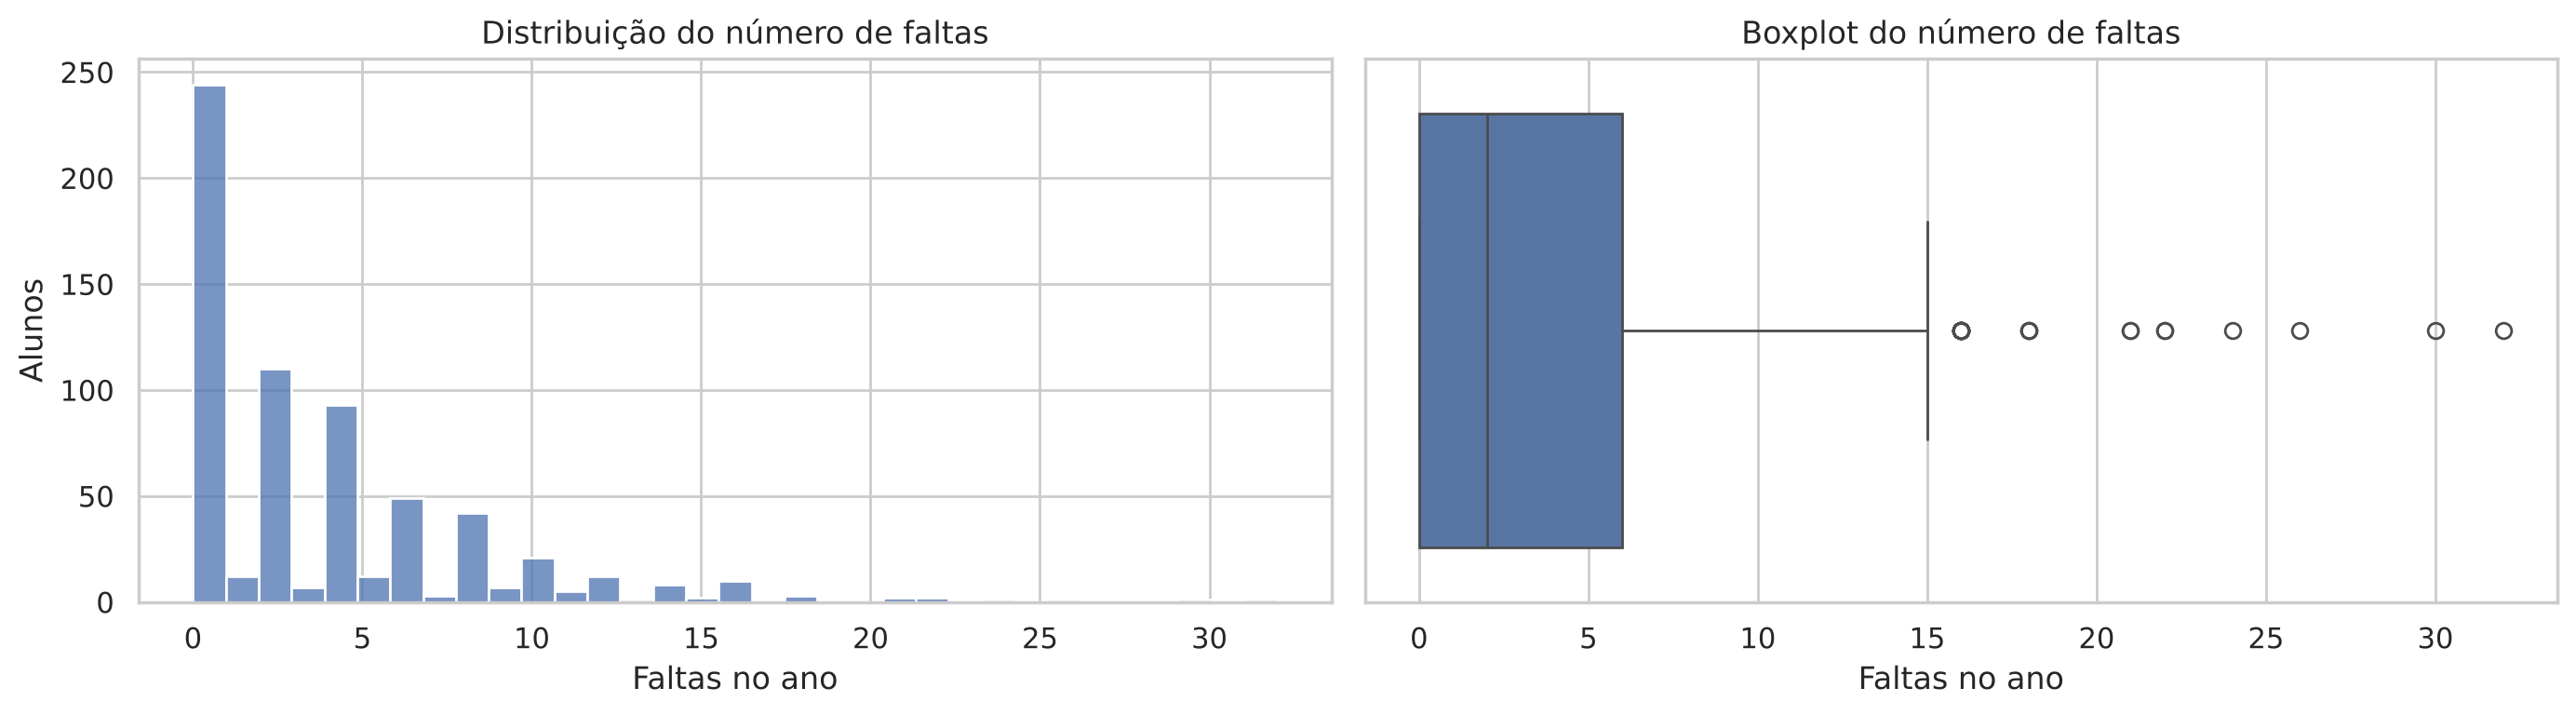

Q1 = 0 | Q3 = 6 | limite superior pelo IQR = 15 faltas
Alunos acima do limite: 21
Nota final média desses alunos: 10.76 (base toda: 11.91)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Numero_de_Faltas"], bins=33, ax=axes[0])
axes[0].set_title("Distribuição do número de faltas"); axes[0].set_xlabel("Faltas no ano"); axes[0].set_ylabel("Alunos")
sns.boxplot(x=df["Numero_de_Faltas"], ax=axes[1])
axes[1].set_title("Boxplot do número de faltas"); axes[1].set_xlabel("Faltas no ano")
plt.tight_layout(); plt.show()

q1, q3 = df["Numero_de_Faltas"].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
atipicos = df[df["Numero_de_Faltas"] > limite_superior]
print(f"Q1 = {q1:.0f} | Q3 = {q3:.0f} | limite superior pelo IQR = {limite_superior:.0f} faltas")
print(f"Alunos acima do limite: {len(atipicos)}")
print(f"Nota final média desses alunos: {atipicos['Nota_Final'].mean():.2f} (base toda: {df['Nota_Final'].mean():.2f})")

A distribuição das faltas é bem assimétrica: metade dos alunos tem até 2 faltas e 75% tem até 6, mas o máximo chega a 32. Pelo critério do IQR, 21 alunos têm mais de 15 faltas. Esses valores são possíveis no contexto escolar (estão bem abaixo do máximo de 93 da documentação), então **não removemos nem cortamos** esses registros. A diferença de escala entre faltas (0 a 32) e as escalas de 1 a 5 é um dos motivos para padronizar as variáveis numéricas nos modelos lineares.

## 2.13 Tempo de estudo e reprovações anteriores

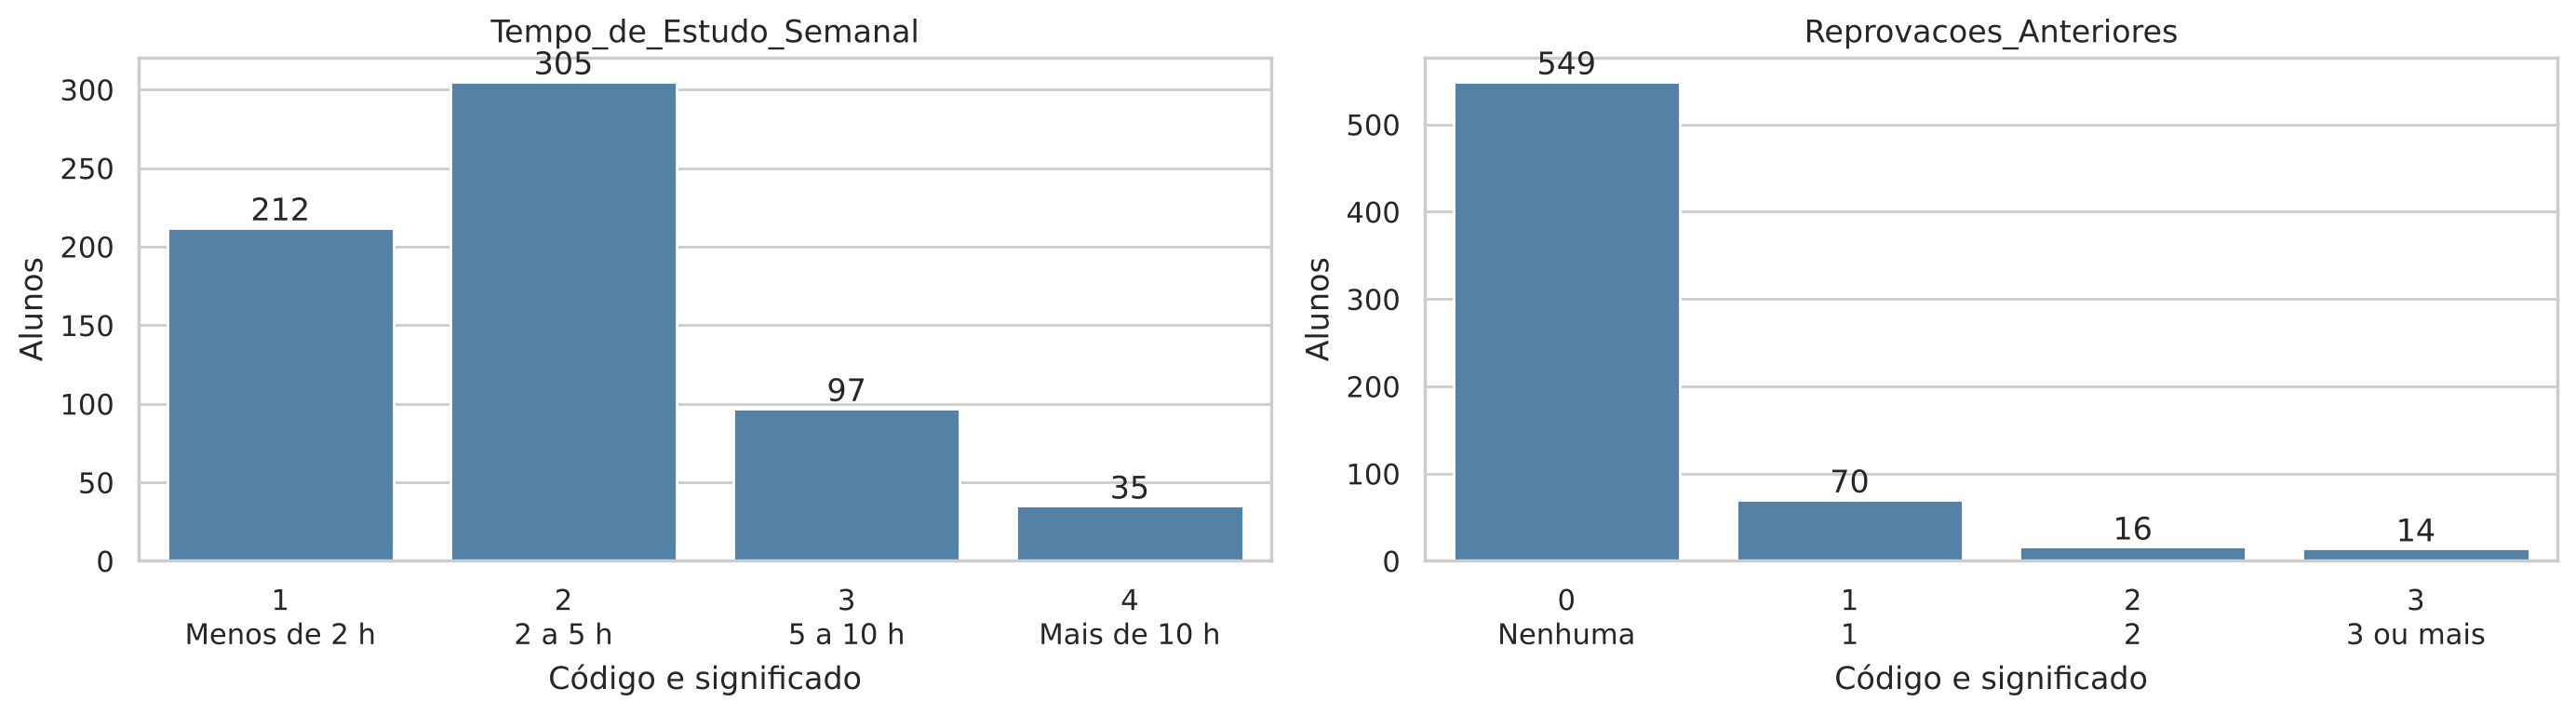

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, coluna in zip(axes, ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.countplot(x=df[coluna], order=ordem, ax=ax, color="steelblue")
    ax.set_xticks(range(len(ordem)))
    ax.set_xticklabels([f"{c}\n{dicionario_codigos[coluna][c]}" for c in ordem])
    ax.set_title(coluna); ax.set_xlabel("Código e significado"); ax.set_ylabel("Alunos")
    ax.bar_label(ax.containers[0])
plt.tight_layout(); plt.show()

517 dos 649 alunos (cerca de 80%) estudam menos de 5 horas por semana (códigos 1 e 2), e só 35 estudam mais de 10 horas. Quanto às reprovações, 549 alunos (84,6%) nunca reprovaram e 100 têm de 1 a 3 reprovações no histórico.

## 2.14 Relações com a nota final

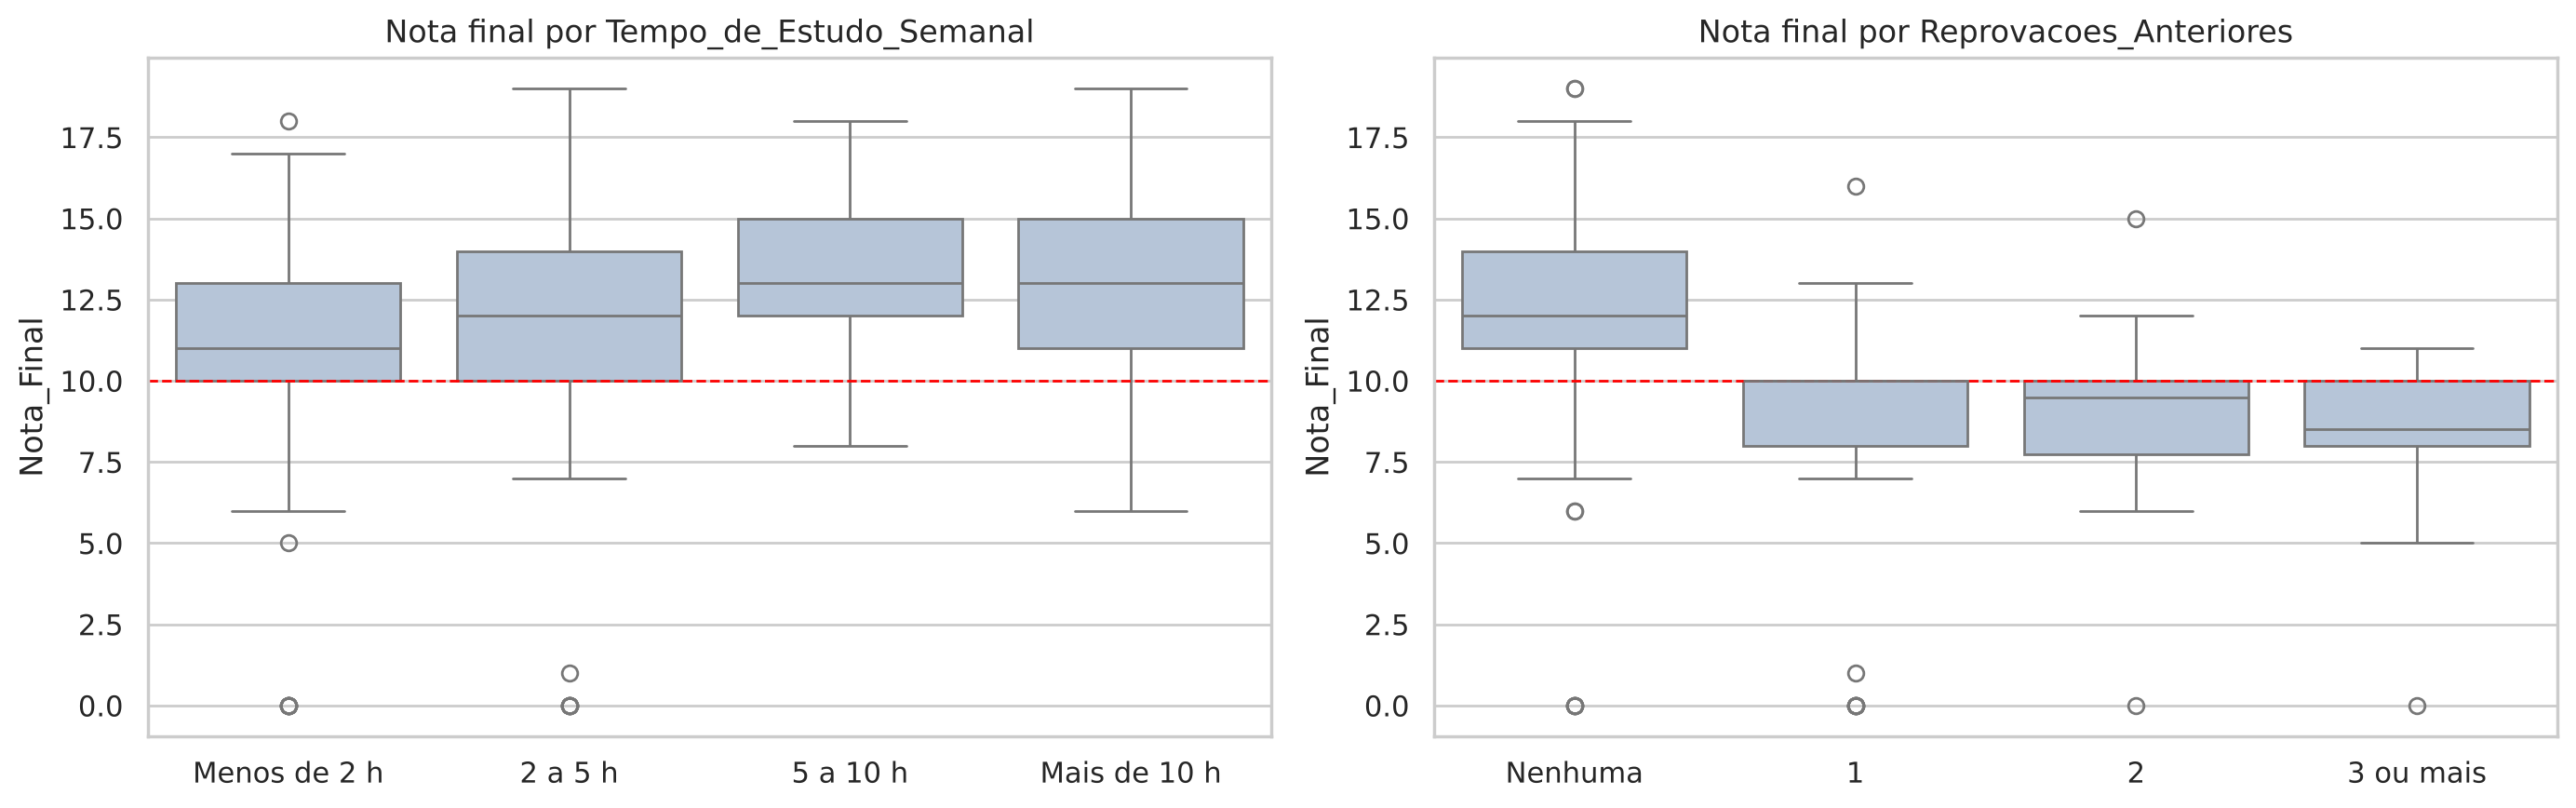

,Alunos,Média da nota final,Mediana
Tempo_de_Estudo_Semanal,,,
1 - Menos de 2 h,212,10.84,11.0
2 - 2 a 5 h,305,12.09,12.0
3 - 5 a 10 h,97,13.23,13.0
4 - Mais de 10 h,35,13.06,13.0


,Alunos,Média da nota final,Mediana
Reprovacoes_Anteriores,,,
0 - Nenhuma,549,12.51,12.0
1 - 1,70,8.64,10.0
2 - 2,16,8.81,9.5
3 - 3 ou mais,14,8.07,8.5


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, coluna in zip(axes, ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.boxplot(x=df[coluna], y=df["Nota_Final"], order=ordem, ax=ax, color="lightsteelblue")
    ax.set_xticks(range(len(ordem)))
    ax.set_xticklabels([dicionario_codigos[coluna][c] for c in ordem])
    ax.axhline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Nota final por {coluna}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

for coluna in ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]:
    resumo = df.groupby(coluna)["Nota_Final"].agg(["count", "mean", "median"]).round(2)
    resumo.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in resumo.index]
    resumo.columns = ["Alunos", "Média da nota final", "Mediana"]
    resumo.index.name = coluna
    display(resumo)

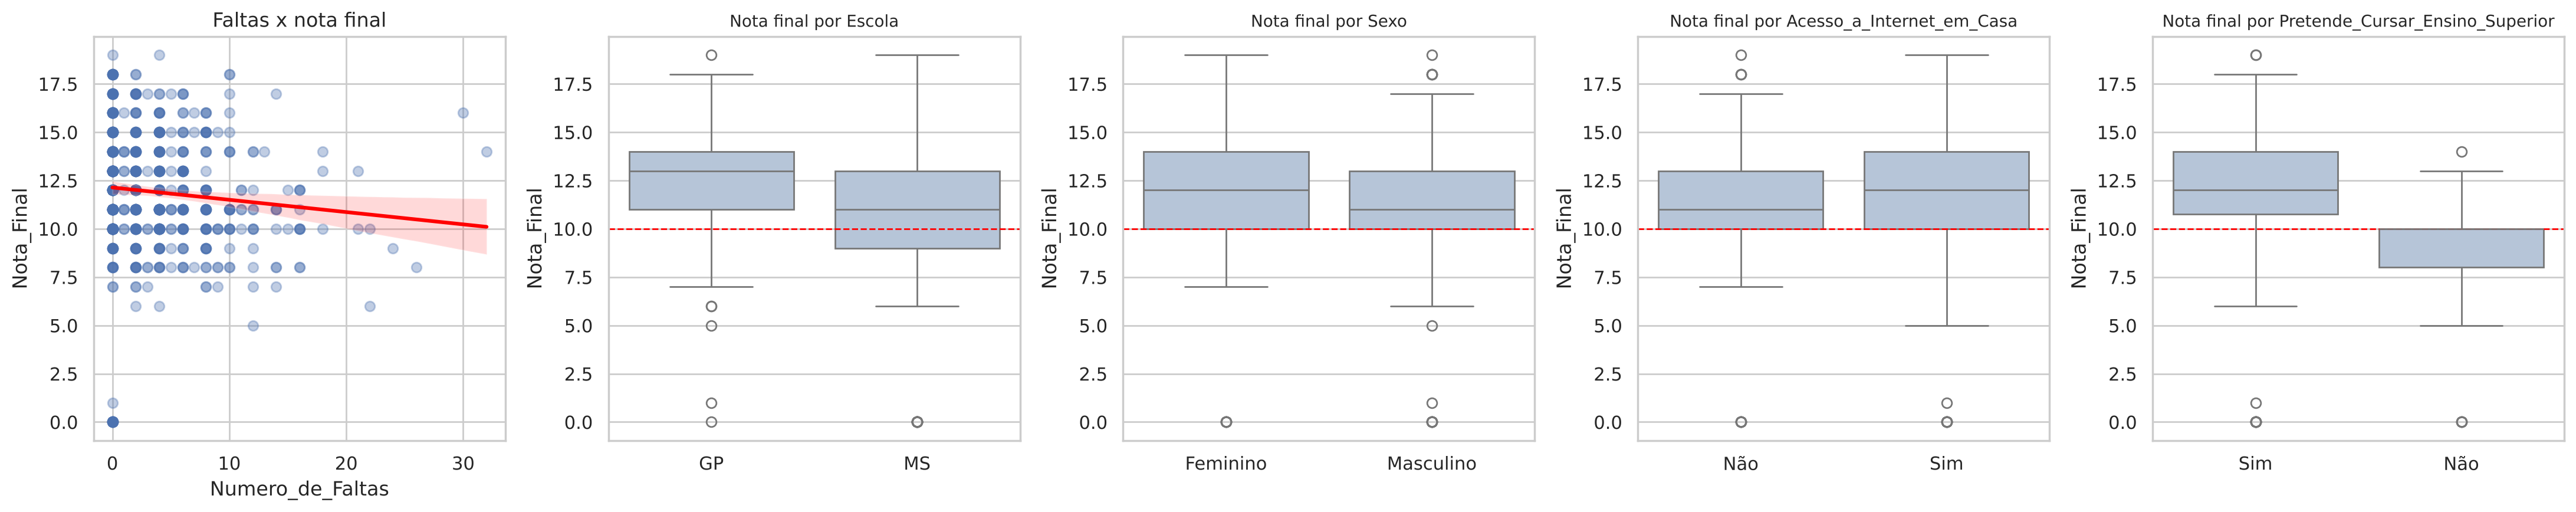

Escola {'GP': 12.58, 'MS': 10.65}
Sexo {'Feminino': 12.25, 'Masculino': 11.41}
Acesso_a_Internet_em_Casa {'Não': 11.03, 'Sim': 12.17}
Pretende_Cursar_Ensino_Superior {'Não': 8.8, 'Sim': 12.28}


In [18]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
sns.regplot(data=df, x="Numero_de_Faltas", y="Nota_Final", ax=axes[0],
            scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
axes[0].set_title("Faltas x nota final")
for ax, coluna in zip(axes[1:], ["Escola", "Sexo", "Acesso_a_Internet_em_Casa", "Pretende_Cursar_Ensino_Superior"]):
    sns.boxplot(data=df, x=coluna, y="Nota_Final", ax=ax, color="lightsteelblue")
    ax.axhline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Nota final por {coluna}", fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

for coluna in ["Escola", "Sexo", "Acesso_a_Internet_em_Casa", "Pretende_Cursar_Ensino_Superior"]:
    print(coluna, df.groupby(coluna)["Nota_Final"].mean().round(2).to_dict())

A nota final sobe com o tempo de estudo: a média vai de 10,84 para quem estuda menos de 2 h por semana até 13,23 para quem estuda de 5 a 10 h (o grupo de mais de 10 h, com só 35 alunos, fica em 13,06). O efeito das reprovações anteriores é ainda maior: quem nunca reprovou tem média 12,51, e quem já reprovou fica entre 8,07 e 8,81, abaixo da nota mínima para aprovação.

As faltas têm relação negativa com a nota, mas fraca: a reta cai pouco e os pontos estão muito espalhados. Entre as variáveis de texto, as maiores diferenças estão em querer cursar o ensino superior (média 12,28 contra 8,80) e na escola (GP 12,58 contra MS 10,65). Sexo e acesso à internet mostram diferenças menores, de cerca de 1 ponto.

## 2.15 Correlação

Usamos a correlação de **Spearman**, que trabalha com a ordem dos valores. Ela é mais adequada que a de Pearson aqui, porque boa parte das variáveis são escalas ordinais (1 a 5, 0 a 4) e não medidas contínuas.

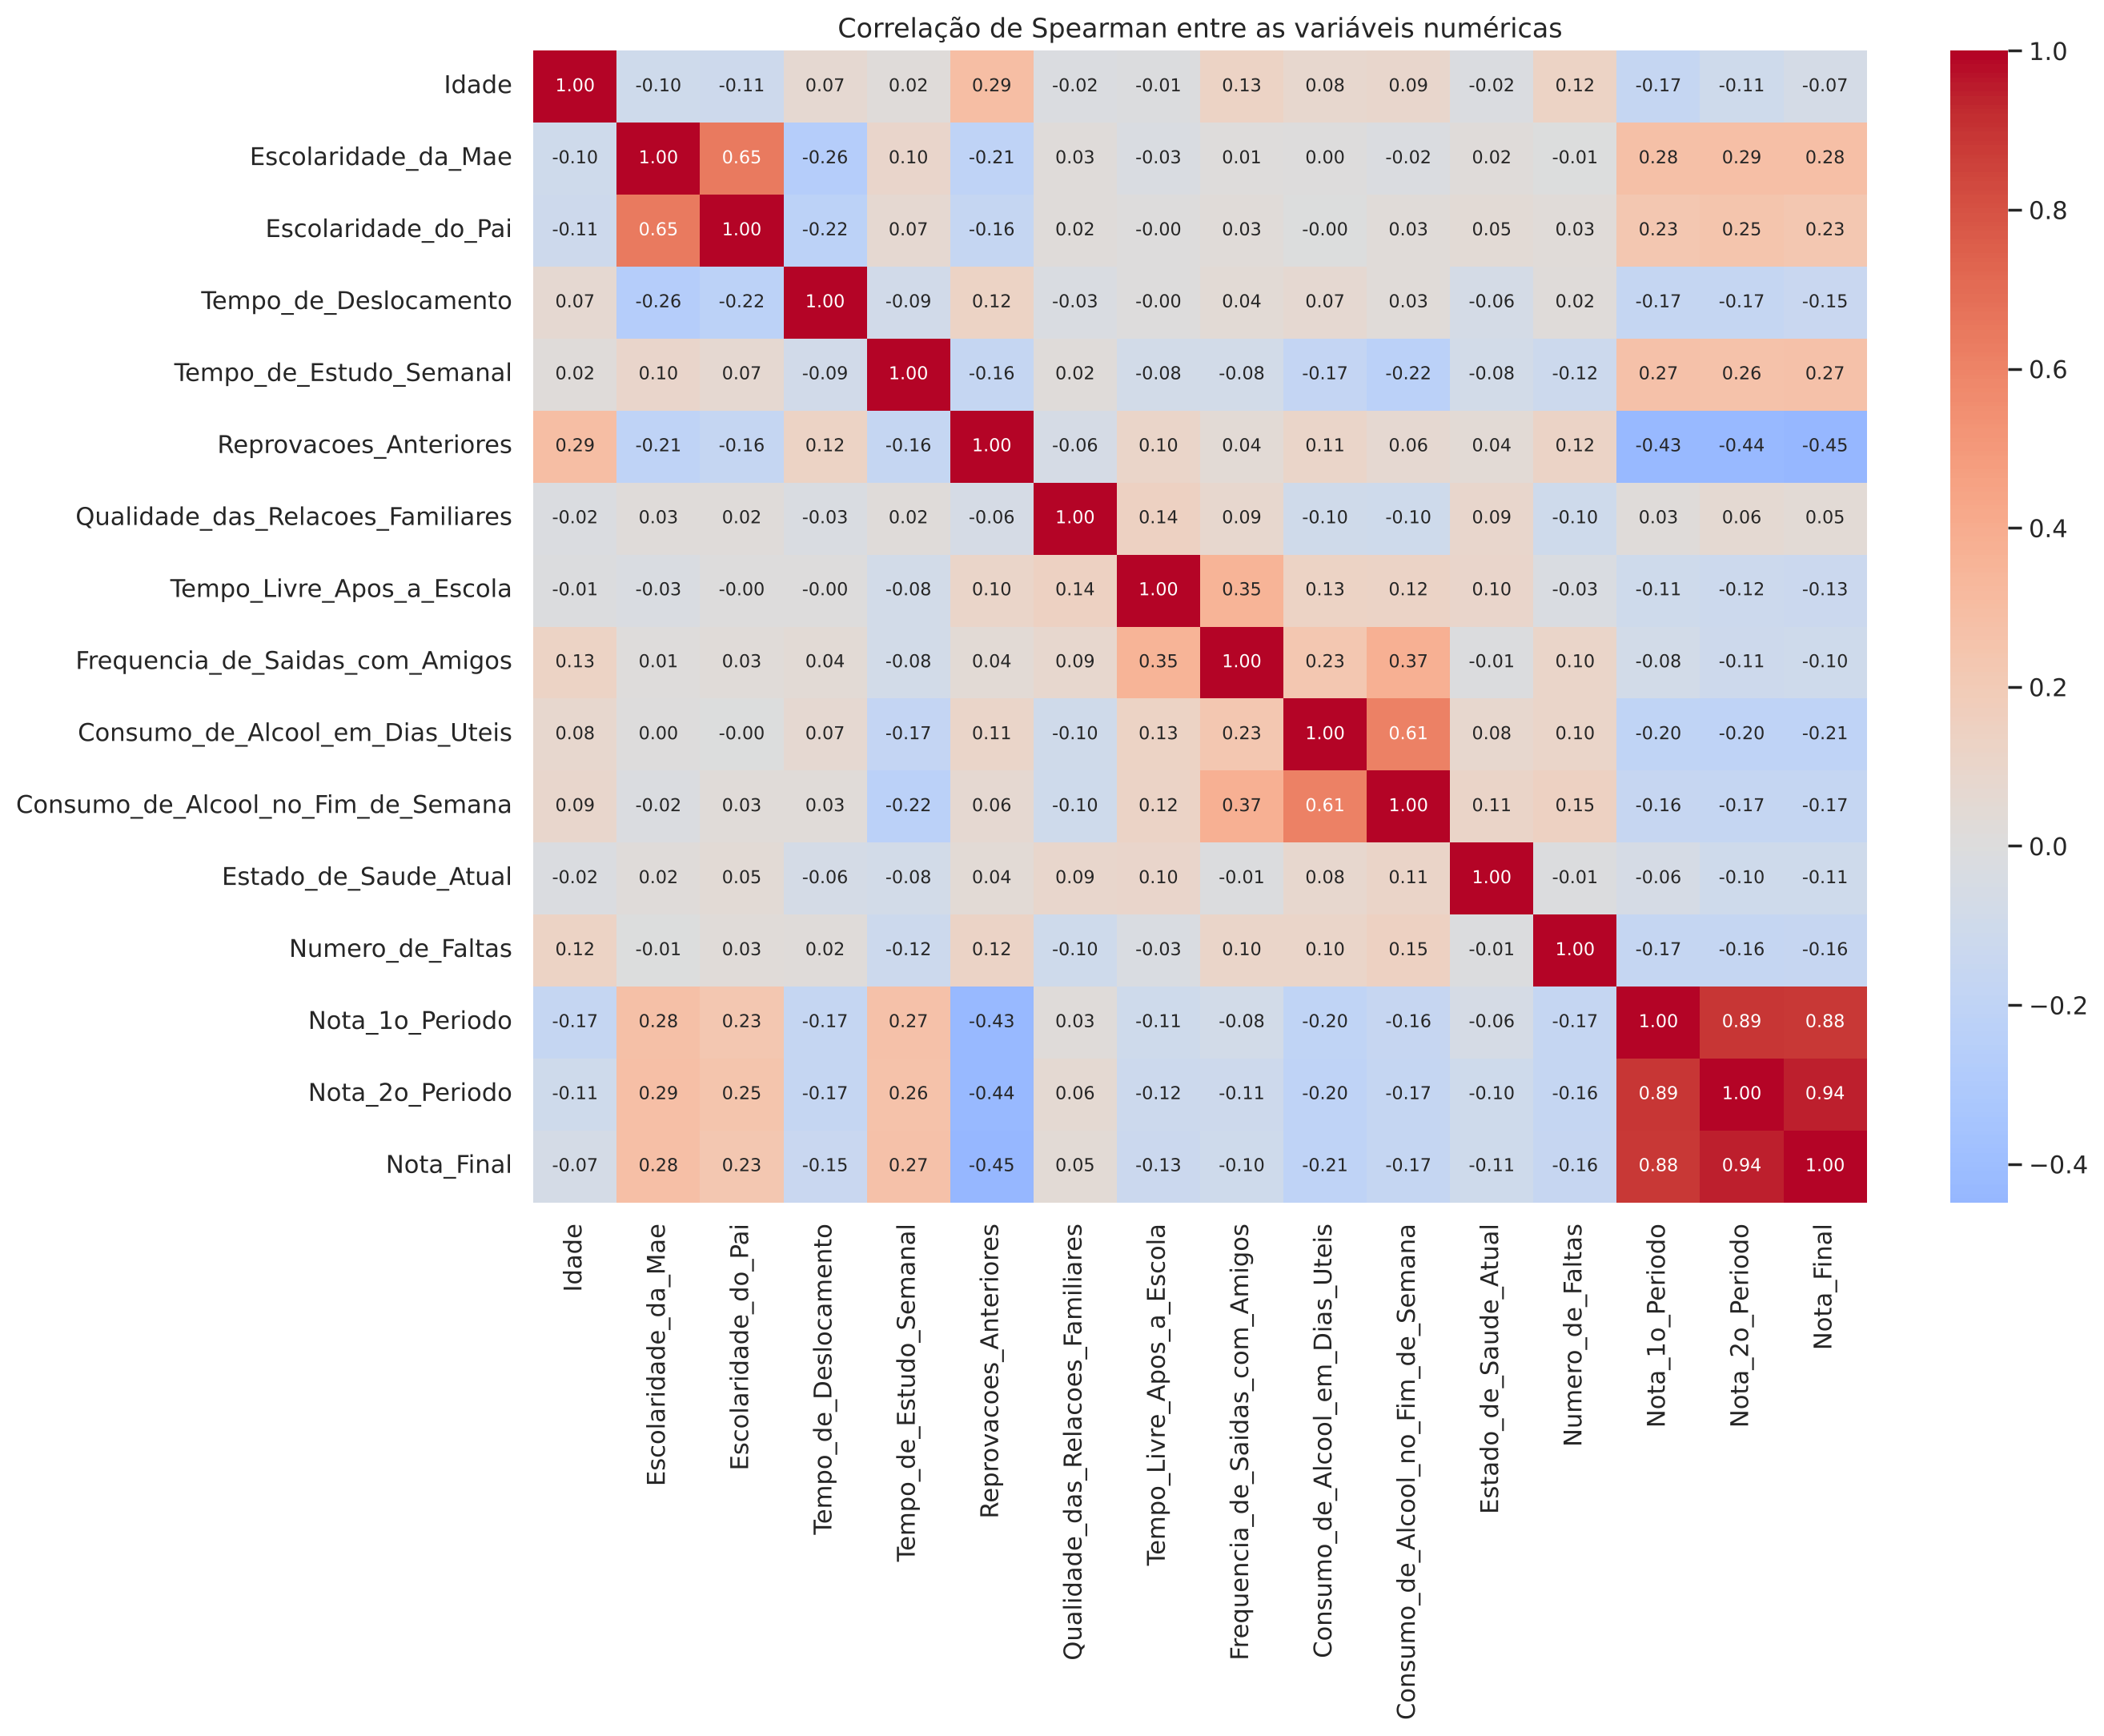

Reprovacoes_Anteriores               -0.448
Consumo_de_Alcool_em_Dias_Uteis      -0.208
Consumo_de_Alcool_no_Fim_de_Semana   -0.171
Numero_de_Faltas                     -0.159
Tempo_de_Deslocamento                -0.147
Tempo_Livre_Apos_a_Escola            -0.128
Estado_de_Saude_Atual                -0.106
Frequencia_de_Saidas_com_Amigos      -0.105
Idade                                -0.066
Qualidade_das_Relacoes_Familiares     0.048
Escolaridade_do_Pai                   0.235
Tempo_de_Estudo_Semanal               0.275
Escolaridade_da_Mae                   0.284
Nota_1o_Periodo                       0.883
Nota_2o_Periodo                       0.944
Name: Nota_Final, dtype: float64

In [19]:
correlacao = df[colunas_numericas].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout(); plt.show()

correlacao["Nota_Final"].drop("Nota_Final").sort_values().round(3)

Com a nota final, as correlações mais fortes são as notas do 2º período (0,94) e do 1º período (0,88). Fora as notas, o destaque é `Reprovacoes_Anteriores` (-0,45), seguida de escolaridade da mãe (0,28), tempo de estudo (0,28), escolaridade do pai (0,24) e consumo de álcool em dias úteis (-0,21). As demais ficam abaixo de 0,2 em módulo, ou seja, sozinhas dizem pouco sobre a nota.

Isso tem consequências para a modelagem:

* As notas parciais são quase a própria resposta. Usá-las num modelo que deveria funcionar no início do ano seria vazamento de informação, e por isso criamos os cenários A e B (Etapa 3).
* Sem as notas, nenhuma variável isolada explica muito, então já esperamos um desempenho bem mais modesto no Cenário A.
* Algumas entradas são correlacionadas entre si: escolaridade da mãe e do pai (0,65) e os dois tipos de consumo de álcool (0,61). Isso deixa os coeficientes da regressão linear instáveis, um motivo a mais para testar regularização (Ridge e Lasso).

## 2.16 Situação final e desbalanceamento das classes

Criamos `Situacao_Final` (Aprovado se nota final >= 10, Reprovado se < 10) apenas para a análise exploratória.

                Alunos      %
Situacao_Final               
Aprovado           549  84.59
Reprovado          100  15.41


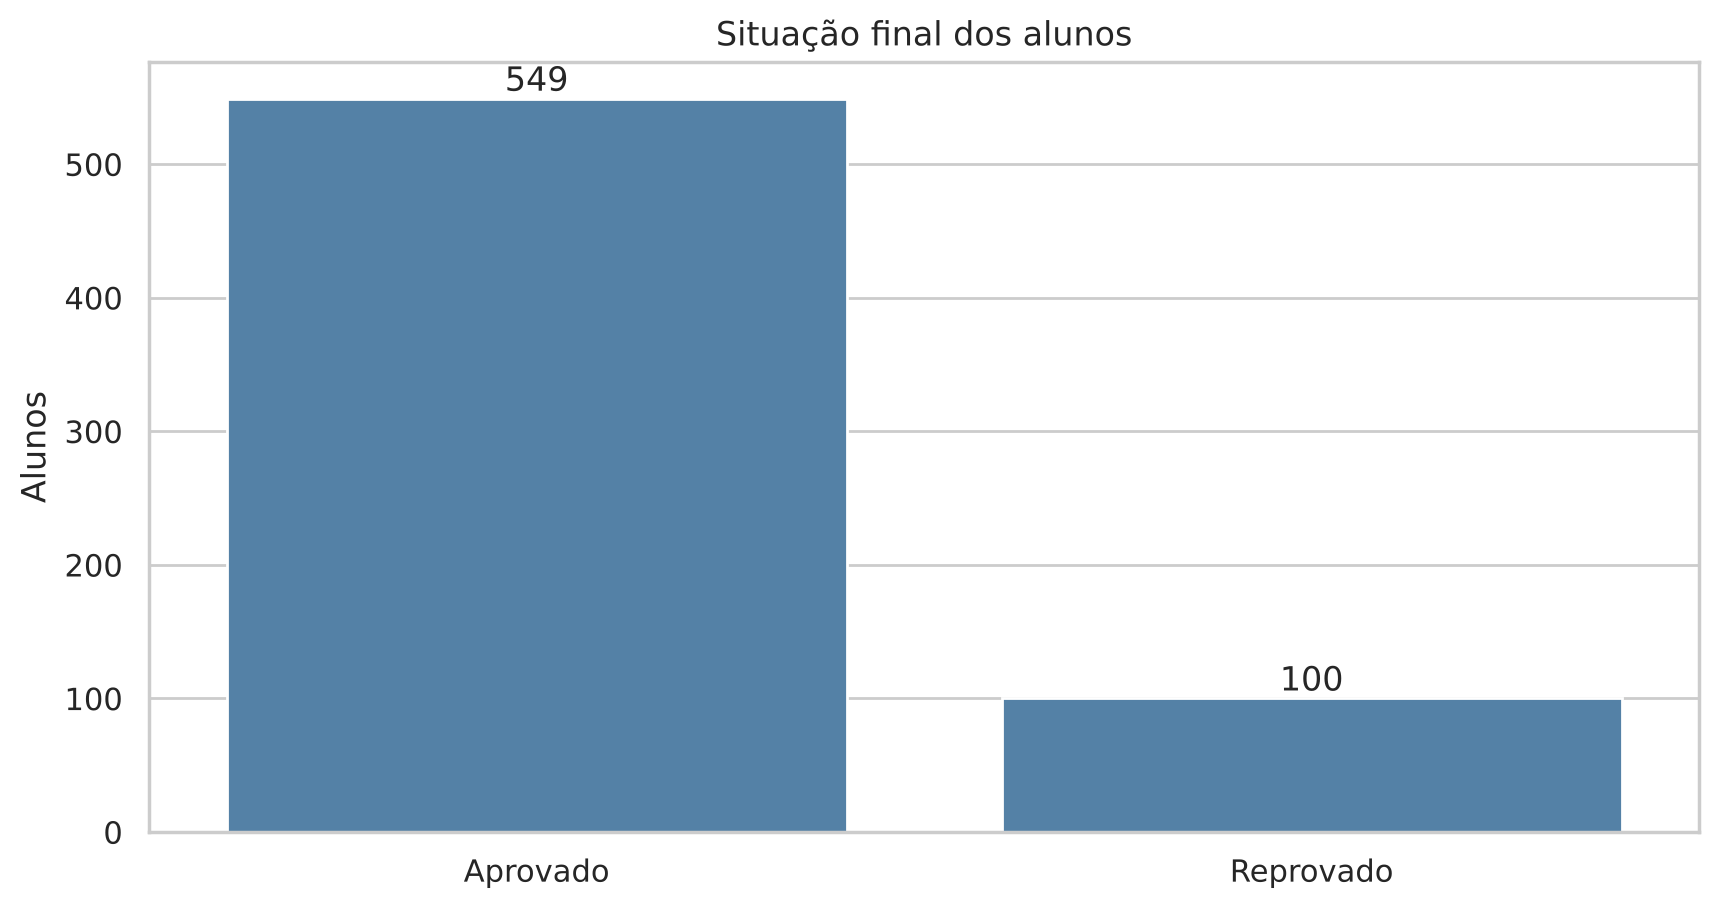

In [20]:
df["Situacao_Final"] = np.where(df["Nota_Final"] >= 10, "Aprovado", "Reprovado")
contagem = df["Situacao_Final"].value_counts()
print(pd.DataFrame({"Alunos": contagem, "%": (contagem / len(df) * 100).round(2)}))

ax = sns.countplot(data=df, x="Situacao_Final", order=["Aprovado", "Reprovado"], color="steelblue")
ax.bar_label(ax.containers[0]); plt.title("Situação final dos alunos"); plt.xlabel(""); plt.ylabel("Alunos")
plt.show()

In [21]:
for coluna in ["Reprovacoes_Anteriores", "Tempo_de_Estudo_Semanal", "Escola", "Acesso_a_Internet_em_Casa"]:
    taxa = pd.crosstab(df[coluna], df["Situacao_Final"], normalize="index").mul(100).round(2)
    if coluna in dicionario_codigos:
        taxa.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in taxa.index]
    taxa.index.name = coluna
    display(taxa.rename(columns={"Aprovado": "% aprovados", "Reprovado": "% reprovados"}))

Situacao_Final,% aprovados,% reprovados
Reprovacoes_Anteriores,,
0 - Nenhuma,90.71,9.29
1 - 1,54.29,45.71
2 - 2,50.00,50.00
3 - 3 ou mais,35.71,64.29


Situacao_Final,% aprovados,% reprovados
Tempo_de_Estudo_Semanal,,
1 - Menos de 2 h,76.42,23.58
2 - 2 a 5 h,86.56,13.44
3 - 5 a 10 h,92.78,7.22
4 - Mais de 10 h,94.29,5.71


Situacao_Final,% aprovados,% reprovados
Escola,,
GP,92.43,7.57
MS,69.91,30.09


Situacao_Final,% aprovados,% reprovados
Acesso_a_Internet_em_Casa,,
Não,78.81,21.19
Sim,86.35,13.65


São 549 aprovados (84,59%) e 100 reprovados (15,41%), ou seja, as classes são desbalanceadas. A taxa de reprovação muda bastante entre os grupos:

* 9,29% entre quem nunca reprovou, contra 45,71% a 64,29% entre quem já reprovou;
* 23,58% entre quem estuda menos de 2 h por semana, contra 7,22% e 5,71% nos dois níveis de mais estudo;
* 30,09% na escola MS, contra 7,57% na GP;
* 21,19% entre quem não tem internet em casa, contra 13,65% entre quem tem.

O desbalanceamento define duas escolhas da classificação: não vamos julgar os modelos pela acurácia (dizer "aprovado" para todo mundo já dá 84,6%) e vamos testar `class_weight="balanced"`, para que o modelo dê mais peso aos reprovados.

## 2.17 Decisões de codificação e padronização

Com base no que vimos, definimos como cada tipo de variável será transformado. **Nada é ajustado aqui**: os transformadores são montados num `ColumnTransformer` e aprendem médias, desvios e categorias **apenas com os dados de treino**, na Etapa 4.

| Tipo de variável | Exemplos | Transformação | Motivo |
|---|---|---|---|
| Binárias de texto | `Sexo`, `Escola`, sim/não | `OneHotEncoder(drop="if_binary")`, vira uma coluna 0/1 | Os modelos só trabalham com números; com duas categorias basta uma coluna |
| Nominais com mais de 2 categorias | `Ocupacao_da_Mae`, `Motivo_da_Escolha_da_Escola` | `OneHotEncoder`, uma coluna 0/1 por categoria | Não existe ordem entre "Saúde" e "Serviços"; transformar em 1, 2, 3 criaria uma ordem falsa |
| Ordinais (códigos) | `Escolaridade_da_Mae`, `Tempo_de_Estudo_Semanal` | Mantidas como número e padronizadas | A ordem tem significado (código 3 estuda mais que código 1) |
| Contínuas / contagens | `Idade`, `Numero_de_Faltas`, notas | `StandardScaler` (média 0, desvio 1) | As escalas são muito diferentes (faltas de 0 a 32, escalas de 1 a 5); isso afeta a regularização e o K-Means |
| Valores ausentes | nenhuma coluna | sem imputação | A base não tem ausentes (seção 2.6) |

Não aplicamos transformação logarítmica nas faltas: os modelos lineares regularizados e o Random Forest funcionaram bem com a padronização, e preferimos manter a variável fácil de interpretar.

In [22]:
binarias = [c for c in colunas_categoricas if df[c].nunique() == 2]
nominais = [c for c in colunas_categoricas if df[c].nunique() > 2]
ordinais = list(dicionario_codigos.keys())
continuas = [c for c in colunas_numericas if c not in ordinais]

print("Binárias:", binarias)
print("Nominais:", nominais)
print("Ordinais (códigos):", ordinais)
print("Contínuas / contagens:", continuas)

Binárias: ['Escola', 'Sexo', 'Tipo_de_Endereco', 'Tamanho_da_Familia', 'Situacao_dos_Pais', 'Apoio_Educacional_da_Escola', 'Apoio_Educacional_Familiar', 'Aulas_Particulares_Pagas', 'Atividades_Extracurriculares', 'Frequentou_Educacao_Infantil', 'Pretende_Cursar_Ensino_Superior', 'Acesso_a_Internet_em_Casa', 'Relacionamento_Amoroso']
Nominais: ['Ocupacao_da_Mae', 'Ocupacao_do_Pai', 'Motivo_da_Escolha_da_Escola', 'Responsavel']
Ordinais (códigos): ['Escolaridade_da_Mae', 'Escolaridade_do_Pai', 'Tempo_de_Deslocamento', 'Tempo_de_Estudo_Semanal', 'Reprovacoes_Anteriores', 'Qualidade_das_Relacoes_Familiares', 'Tempo_Livre_Apos_a_Escola', 'Frequencia_de_Saidas_com_Amigos', 'Consumo_de_Alcool_em_Dias_Uteis', 'Consumo_de_Alcool_no_Fim_de_Semana', 'Estado_de_Saude_Atual']
Contínuas / contagens: ['Idade', 'Numero_de_Faltas', 'Nota_1o_Periodo', 'Nota_2o_Periodo', 'Nota_Final']


## 2.18 Resumo da qualidade da base

In [23]:
pd.DataFrame({
    "Indicador": ["Estudantes", "Variáveis originais", "Valores ausentes", "Linhas duplicadas",
                  "Valores fora da escala", "Alunos com nota final 0", "Alunos com mais de 15 faltas",
                  "% de reprovados"],
    "Resultado": [len(df), 33, int(df.isnull().sum().sum()), int(df.duplicated().sum()),
                  int(verificacao["Fora da faixa"].sum()), int((df["Nota_Final"] == 0).sum()),
                  len(atipicos), f'{(df["Situacao_Final"] == "Reprovado").mean() * 100:.2f}%'],
})

,Indicador,Resultado
0,Estudantes,649
1,Variáveis originais,33
2,Valores ausentes,0
3,Linhas duplicadas,0
4,Valores fora da escala,0
5,Alunos com nota final 0,15
6,Alunos com mais de 15 faltas,21
7,% de reprovados,15.41%


### Conclusão da Etapa 2: como a EDA orienta a modelagem

1. **Ausentes e duplicados:** não existem, então não há imputação nem exclusão de linhas.
2. **Notas zero e faltas altas:** são casos reais (prováveis abandonos e alunos muito faltosos) e foram mantidos. Esperamos que os zeros aumentem o erro da regressão.
3. **Escala e codificação:** as variáveis têm escalas muito diferentes e há 17 colunas de texto. Usaremos `StandardScaler` e `OneHotEncoder` dentro de um `Pipeline`, ajustados só no treino.
4. **Vazamento temporal:** as notas parciais têm correlação de 0,88 e 0,94 com a nota final, e as faltas são do ano inteiro. Por isso a modelagem é feita em dois cenários: A, sem essas variáveis, e B, com elas.
5. **Desbalanceamento:** 15,41% de reprovados. Na classificação usaremos divisão estratificada, `class_weight="balanced"` e métricas focadas na classe reprovado (recall, precisão e F1).

---

# Etapa 3: Definição da Tarefa

> **Enunciado da Especificação (Etapa 3):** *"3. Definição da tarefa: supervisionada ou não supervisionada; se supervisionada, regressão ou classificação."*

| Tarefa | Tipo | Alvo | Métricas |
|---|---|---|---|
| Prever a nota final | Supervisionada - **regressão** | `Nota_Final` (0 a 20) | MAE (erro médio em pontos), RMSE e R² |
| Prever reprovação | Supervisionada - **classificação** binária | `Risco_Reprovacao` (1 = reprovado, 0 = aprovado) | Recall, precisão e F1 da classe 1, matriz de confusão. A acurácia aparece só para comparação, porque com 15% de reprovados um modelo que chuta "aprovado" para todos já acerta 85% |
| Encontrar perfis de alunos | **Não supervisionada** - agrupamento | não há alvo | Inércia (método do cotovelo) e coeficiente de silhueta; PCA para visualizar |

### 3.1 Variáveis disponíveis em cada cenário

Uma variável só pode entrar no modelo se estiver disponível no momento em que a previsão é feita:

* `Nota_Final`, `Situacao_Final` e `Risco_Reprovacao` são a própria resposta e nunca entram como entrada.
* `Nota_1o_Periodo` e `Nota_2o_Periodo` só existem depois desses períodos, então ficam **fora do Cenário A** e entram no Cenário B.
* `Numero_de_Faltas` é o total de faltas do ano, vindo do boletim. No início do ano esse número ainda não existe, então também fica **fora do Cenário A**. No Cenário B usamos as faltas sabendo que é uma aproximação (o ideal seria ter só as faltas até o 2º período; voltamos a isso nas limitações).

In [24]:
df["Risco_Reprovacao"] = (df["Nota_Final"] < 10).astype(int)

colunas_resposta = ["Nota_Final", "Situacao_Final", "Risco_Reprovacao"]
so_no_cenario_b = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Numero_de_Faltas"]

features_a = [c for c in df.columns if c not in colunas_resposta + so_no_cenario_b]
features_b = features_a + so_no_cenario_b

def separar_tipos(features):
    numericas = [c for c in features if c in colunas_numericas]
    categoricas = [c for c in features if c in colunas_categoricas]
    return numericas, categoricas

cenarios = {
    "A": (features_a, *separar_tipos(features_a)),
    "B": (features_b, *separar_tipos(features_b)),
}
for nome, (feats, num, cat) in cenarios.items():
    print(f"Cenário {nome}: {len(feats)} variáveis ({len(num)} numéricas e {len(cat)} categóricas)")

Cenário A: 29 variáveis (12 numéricas e 17 categóricas)
Cenário B: 32 variáveis (15 numéricas e 17 categóricas)


### 3.2 Divisão treino e teste (antes de qualquer ajuste)

Separamos 80% dos alunos para treino e 20% para teste, com estratificação pelo `Risco_Reprovacao` para manter a mesma proporção de reprovados nos dois conjuntos. A mesma divisão é usada na regressão e na classificação. O conjunto de teste fica guardado e só é usado uma vez, na Etapa 5.

In [25]:
idx_treino, idx_teste = train_test_split(df.index, test_size=0.20, random_state=SEMENTE,
                                         stratify=df["Risco_Reprovacao"])

divisao = pd.DataFrame({
    "Alunos": [len(idx_treino), len(idx_teste)],
    "Reprovados": [df.loc[idx_treino, "Risco_Reprovacao"].sum(), df.loc[idx_teste, "Risco_Reprovacao"].sum()],
    "% reprovados": [round(df.loc[idx_treino, "Risco_Reprovacao"].mean() * 100, 2),
                     round(df.loc[idx_teste, "Risco_Reprovacao"].mean() * 100, 2)],
}, index=["Treino", "Teste"])
divisao

,Alunos,Reprovados,% reprovados
Treino,519,80,15.41
Teste,130,20,15.38


---

# Etapa 4: Construção do Modelo

> **Enunciado da Especificação (Etapa 4):** *"4. Construção do modelo: algoritmos adequados ao problema, sempre comparados com uma referência simples (por exemplo, prever a média ou a classe mais comum)."*

Todos os modelos supervisionados são montados como `Pipeline(pré-processamento + modelo)`. Assim, o `StandardScaler` e o `OneHotEncoder` são ajustados de novo em cada rodada, só com os dados de treino daquela rodada.

Para escolher hiperparâmetros (força da regularização, profundidade das árvores) e comparar os modelos, usamos **validação cruzada com 5 partes dentro do conjunto de treino** (`GridSearchCV`). O teste não participa de nenhuma escolha.

In [26]:
def criar_preprocessador(numericas, categoricas):
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categoricas),
    ])

def nome_parametros(params):
    return ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in params.items()) or "-"

def dados(cenario, alvo):
    feats = cenarios[cenario][0]
    return (df.loc[idx_treino, feats], df.loc[idx_teste, feats],
            df.loc[idx_treino, alvo], df.loc[idx_teste, alvo])

## 4.1 Regressão - `Nota_Final`

* **Referência:** `DummyRegressor`, que prevê sempre a nota média do treino.
* **Regressão Linear:** modelo linear sem regularização.
* **Ridge:** regressão linear com regularização L2 (encolhe os coeficientes).
* **Lasso:** regressão linear com regularização L1 (pode zerar coeficientes de variáveis fracas).
* **Random Forest:** conjunto de árvores; limitamos a profundidade e o tamanho mínimo das folhas para não decorar o treino.

In [27]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def modelos_regressao():
    return {
        "Referência (média)": (DummyRegressor(strategy="mean"), {}),
        "Regressão Linear": (LinearRegression(), {}),
        "Ridge (L2)": (Ridge(), {"modelo__alpha": [0.1, 1, 10, 30, 100]}),
        "Lasso (L1)": (Lasso(max_iter=20000), {"modelo__alpha": [0.01, 0.03, 0.1, 0.3]}),
        "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=SEMENTE, n_jobs=-1),
                          {"modelo__max_depth": [3, 5, 8], "modelo__min_samples_leaf": [1, 5, 10]}),
    }

def construir_regressao(cenario):
    X_tr, _, y_tr, _ = dados(cenario, "Nota_Final")
    _, num, cat = cenarios[cenario]
    linhas, ajustados = [], {}
    for nome, (modelo, grade) in modelos_regressao().items():
        pipe = Pipeline([("prep", criar_preprocessador(num, cat)), ("modelo", modelo)])
        busca = GridSearchCV(pipe, grade, cv=cv_reg, scoring="neg_mean_absolute_error",
                             return_train_score=True, n_jobs=-1)
        busca.fit(X_tr, y_tr)
        i = busca.best_index_
        linhas.append({
            "Modelo": nome,
            "Hiperparâmetros escolhidos": nome_parametros(busca.best_params_),
            "MAE treino (CV)": -busca.cv_results_["mean_train_score"][i],
            "MAE validação (CV)": -busca.cv_results_["mean_test_score"][i],
            "Desvio entre partes": busca.cv_results_["std_test_score"][i],
        })
        ajustados[nome] = busca.best_estimator_
    return pd.DataFrame(linhas).round(3), ajustados

cv_reg_a, modelos_reg_a = construir_regressao("A")
cv_reg_b, modelos_reg_b = construir_regressao("B")

print("Cenário A - início do ano (validação cruzada no treino)")
display(cv_reg_a)
print("Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)")
display(cv_reg_b)

escolhido_reg_a = cv_reg_a.iloc[1:].sort_values("MAE validação (CV)").iloc[0]["Modelo"]
escolhido_reg_b = cv_reg_b.iloc[1:].sort_values("MAE validação (CV)").iloc[0]["Modelo"]
print(f"Escolhido pela validação: Cenário A = {escolhido_reg_a} | Cenário B = {escolhido_reg_b}")

Cenário A - início do ano (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,MAE treino (CV),MAE validação (CV),Desvio entre partes
0,Referência (média),-,2.355,2.364,0.189
1,Regressão Linear,-,1.813,1.970,0.088
2,Ridge (L2),alpha=30,1.812,1.925,0.101
3,Lasso (L1),alpha=0.03,1.819,1.933,0.093
4,Random Forest,"max_depth=8, min_samples_leaf=5",1.401,1.916,0.097


Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,MAE treino (CV),MAE validação (CV),Desvio entre partes
0,Referência (média),-,2.355,2.364,0.189
1,Regressão Linear,-,0.756,0.848,0.100
2,Ridge (L2),alpha=30,0.751,0.813,0.066
3,Lasso (L1),alpha=0.3,0.765,0.767,0.068
4,Random Forest,"max_depth=3, min_samples_leaf=1",0.718,0.789,0.082


Escolhido pela validação: Cenário A = Random Forest | Cenário B = Lasso (L1)


Na validação cruzada, todos os modelos superam a referência nos dois cenários.

* **Cenário A:** a referência erra em média 2,36 pontos. Os modelos ficam entre 1,92 e 1,97 pontos, muito próximos entre si: a diferença entre eles (menos de 0,06 ponto) é menor que a variação entre as partes da validação (cerca de 0,1). O Random Forest teve o menor erro de validação, mas também a maior distância entre treino (1,40) e validação (1,92), sinal de que ele aprende detalhes do treino que não se repetem em alunos novos.
* **Cenário B:** com as notas parciais, o erro cai para cerca de 0,8 ponto. O Lasso teve o menor erro de validação (0,77), com `alpha=0,3`.

O modelo de cada cenário foi escolhido aqui, pela validação, e não pelo resultado no teste.

## 4.2 Classificação - `Risco_Reprovacao`

* **Referência:** `DummyClassifier`, que prevê sempre a classe mais comum (aprovado).
* **Regressão Logística sem balanceamento:** para mostrar o efeito do desbalanceamento.
* **Regressão Logística balanceada:** `class_weight="balanced"` dá mais peso aos reprovados; a força da regularização L2 (`C`) é escolhida na validação.
* **Random Forest balanceado:** também com `class_weight="balanced"` e profundidade limitada.

Na validação cruzada usamos partes estratificadas e escolhemos os hiperparâmetros pelo **F1 da classe reprovado**, que equilibra encontrar reprovados (recall) e não gerar alarmes demais (precisão).

In [28]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
metricas_cv = {"f1": "f1", "recall": "recall", "precisao": "precision"}

def modelos_classificacao():
    return {
        "Referência (classe mais comum)": (DummyClassifier(strategy="most_frequent"), {}),
        "Logística sem balanceamento": (LogisticRegression(max_iter=2000), {}),
        "Logística balanceada (L2)": (LogisticRegression(class_weight="balanced", max_iter=2000),
                                      {"modelo__C": [0.01, 0.05, 0.1, 0.5, 1, 10]}),
        "Random Forest balanceado": (RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                            random_state=SEMENTE, n_jobs=-1),
                                     {"modelo__max_depth": [3, 5, 8], "modelo__min_samples_leaf": [1, 5, 10]}),
    }

def construir_classificacao(cenario):
    X_tr, _, y_tr, _ = dados(cenario, "Risco_Reprovacao")
    _, num, cat = cenarios[cenario]
    linhas, ajustados = [], {}
    for nome, (modelo, grade) in modelos_classificacao().items():
        pipe = Pipeline([("prep", criar_preprocessador(num, cat)), ("modelo", modelo)])
        busca = GridSearchCV(pipe, grade, cv=cv_clf, scoring=metricas_cv, refit="f1",
                             return_train_score=True, n_jobs=-1, error_score="raise")
        busca.fit(X_tr, y_tr)
        i, r = busca.best_index_, busca.cv_results_
        linhas.append({
            "Modelo": nome,
            "Hiperparâmetros escolhidos": nome_parametros(busca.best_params_),
            "Recall validação (CV)": r["mean_test_recall"][i],
            "Precisão validação (CV)": r["mean_test_precisao"][i],
            "F1 treino (CV)": r["mean_train_f1"][i],
            "F1 validação (CV)": r["mean_test_f1"][i],
        })
        ajustados[nome] = busca.best_estimator_
    return pd.DataFrame(linhas).round(3), ajustados

import warnings
with warnings.catch_warnings():
    # o Dummy nunca prevê a classe 1, então a precisão dele fica indefinida (aviso esperado)
    warnings.simplefilter("ignore")
    cv_clf_a, modelos_clf_a = construir_classificacao("A")
    cv_clf_b, modelos_clf_b = construir_classificacao("B")

print("Cenário A - início do ano (validação cruzada no treino)")
display(cv_clf_a)
print("Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)")
display(cv_clf_b)

escolhido_clf_a = cv_clf_a.iloc[1:].sort_values("F1 validação (CV)").iloc[-1]["Modelo"]
escolhido_clf_b = cv_clf_b.iloc[1:].sort_values("F1 validação (CV)").iloc[-1]["Modelo"]
print(f"Escolhido pela validação: Cenário A = {escolhido_clf_a} | Cenário B = {escolhido_clf_b}")

Cenário A - início do ano (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000
1,Logística sem balanceamento,-,0.312,0.564,0.522,0.394
2,Logística balanceada (L2),C=0.01,0.650,0.381,0.554,0.478
3,Random Forest balanceado,"max_depth=5, min_samples_leaf=5",0.675,0.411,0.682,0.508


Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000
1,Logística sem balanceamento,-,0.650,0.776,0.861,0.698
2,Logística balanceada (L2),C=0.1,0.912,0.621,0.791,0.736
3,Random Forest balanceado,"max_depth=8, min_samples_leaf=1",0.875,0.752,0.983,0.803


Escolhido pela validação: Cenário A = Random Forest balanceado | Cenário B = Random Forest balanceado


* A referência tem recall zero: ela nunca aponta um reprovado.
* Sem balanceamento, a Logística encontra só 31% dos reprovados na validação do Cenário A, porque aprende que dizer "aprovado" quase sempre é o caminho mais seguro.
* Com `class_weight="balanced"`, o recall da Logística no Cenário A sobe para 65%, com precisão menor (38%). O `C` escolhido foi 0,01, uma regularização forte: com apenas 80 reprovados no treino, um modelo mais contido generaliza melhor.
* O Random Forest balanceado teve o maior F1 de validação nos dois cenários (0,51 no A e 0,80 no B) e por isso foi o escolhido. No Cenário B, porém, o F1 de treino dele é 0,98, quase perfeito, o que indica sobreajuste. Isso é conferido no teste e na Etapa 6.

## 4.3 Agrupamento - K-Means com PCA

Usamos as 13 variáveis numéricas de família, rotina e comportamento, **sem as notas**. Como não existe alvo, não há risco de vazamento da resposta, e o agrupamento é usado de forma descritiva sobre todos os alunos. As variáveis são padronizadas porque o K-Means usa distância, e sem isso as faltas (0 a 32) dominariam as escalas de 1 a 5.

Para escolher o número de grupos (k), testamos de 2 a 8 e olhamos a inércia (método do cotovelo) e o coeficiente de silhueta (vai de -1 a 1; quanto maior, mais separados estão os grupos).

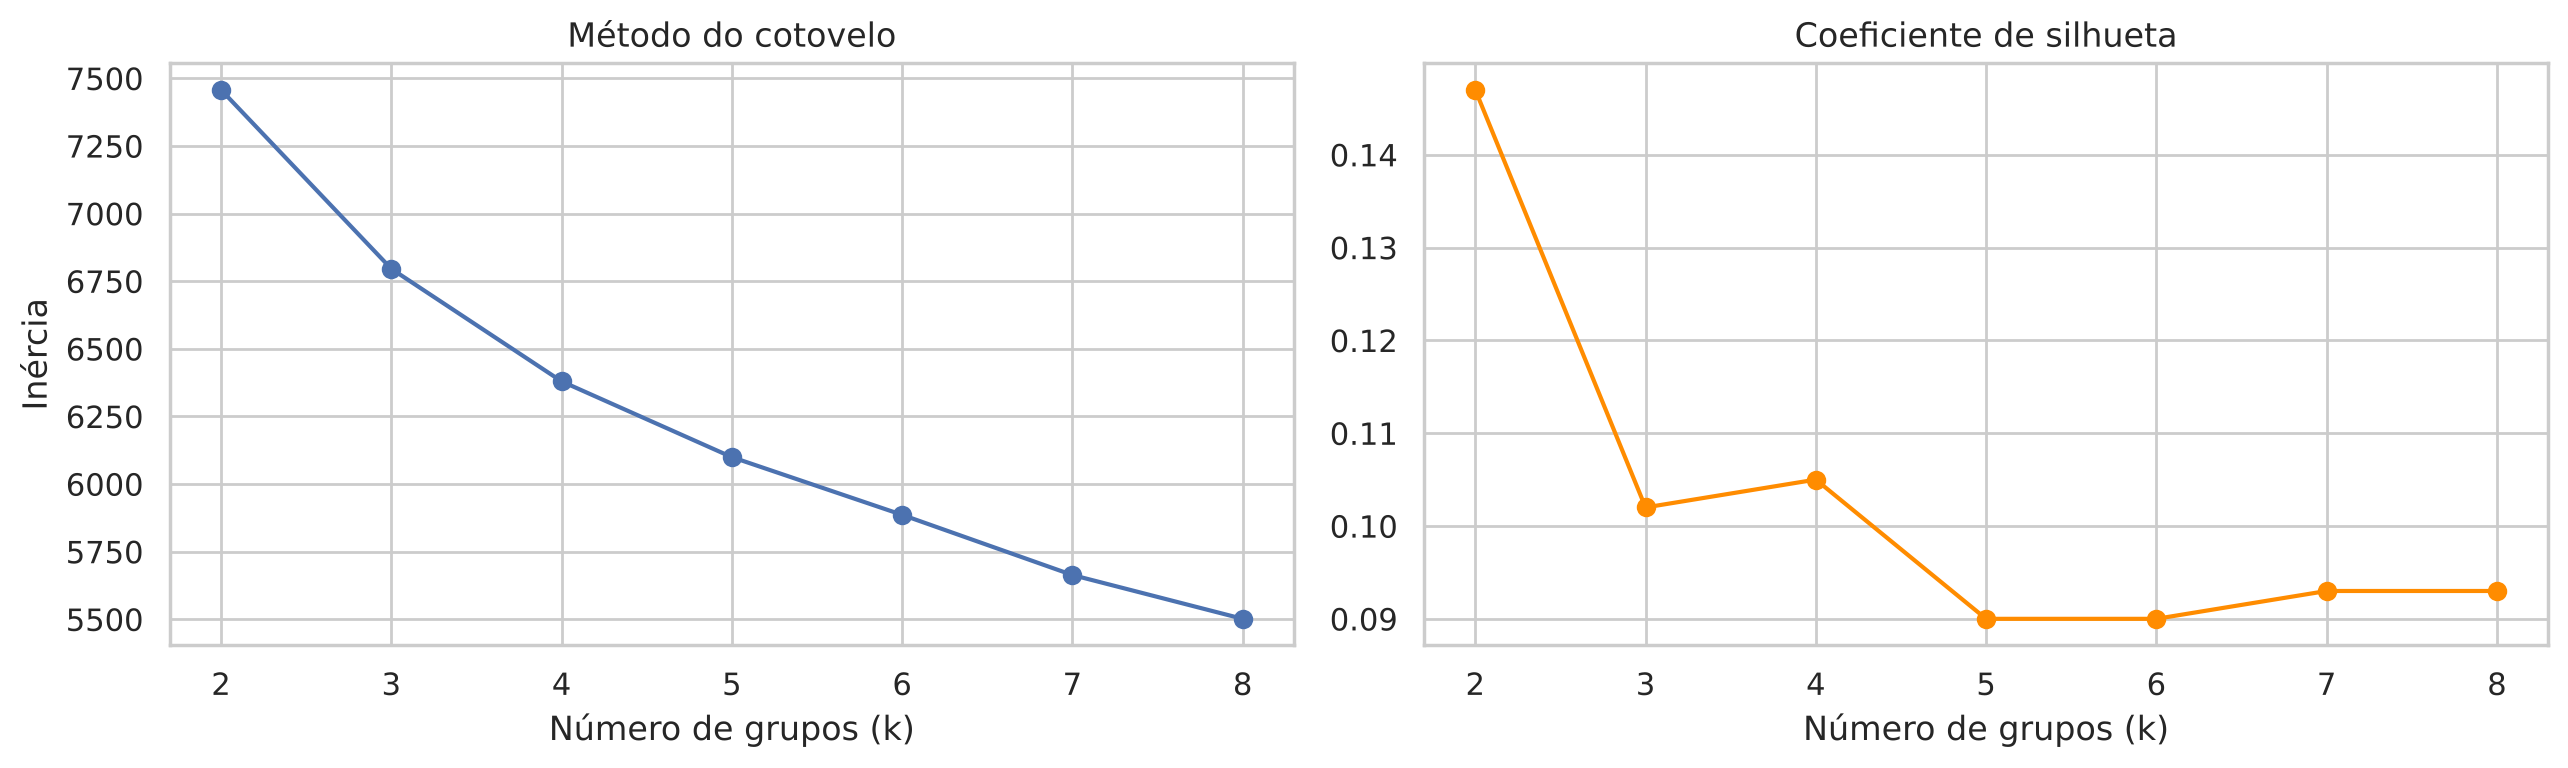

,k,Inércia,Silhueta
0,2,7457.7,0.147
1,3,6795.9,0.102
2,4,6379.6,0.105
3,5,6099.4,0.090
4,6,5886.0,0.090
5,7,5663.5,0.093
6,8,5501.5,0.093


In [29]:
colunas_cluster = ["Idade", "Escolaridade_da_Mae", "Escolaridade_do_Pai", "Tempo_de_Deslocamento",
                   "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores", "Qualidade_das_Relacoes_Familiares",
                   "Tempo_Livre_Apos_a_Escola", "Frequencia_de_Saidas_com_Amigos",
                   "Consumo_de_Alcool_em_Dias_Uteis", "Consumo_de_Alcool_no_Fim_de_Semana",
                   "Estado_de_Saude_Atual", "Numero_de_Faltas"]

X_cluster = StandardScaler().fit_transform(df[colunas_cluster])

avaliacao_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(X_cluster)
    avaliacao_k.append({"k": k, "Inércia": round(km.inertia_, 1),
                        "Silhueta": round(silhouette_score(X_cluster, km.labels_), 3)})
avaliacao_k = pd.DataFrame(avaliacao_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(avaliacao_k["k"], avaliacao_k["Inércia"], marker="o"); axes[0].set_title("Método do cotovelo")
axes[0].set_xlabel("Número de grupos (k)"); axes[0].set_ylabel("Inércia")
axes[1].plot(avaliacao_k["k"], avaliacao_k["Silhueta"], marker="o", color="darkorange")
axes[1].set_title("Coeficiente de silhueta"); axes[1].set_xlabel("Número de grupos (k)")
plt.tight_layout(); plt.show()
avaliacao_k

A inércia cai de forma gradual, sem um "cotovelo" bem marcado, e a silhueta é baixa para qualquer k (no máximo 0,147, com k=2). Isso quer dizer que os alunos não formam grupos naturalmente separados: os perfis se sobrepõem.

Escolhemos **k = 3**. Com k=2 a silhueta é um pouco maior, mas dois grupos dizem pouco para a coordenação. A partir de k=3 a silhueta fica praticamente estável (0,09 a 0,10), então não há ganho em criar mais grupos, e três perfis são fáceis de descrever e de usar. Tratamos os grupos como um resumo de perfis, não como categorias exatas.

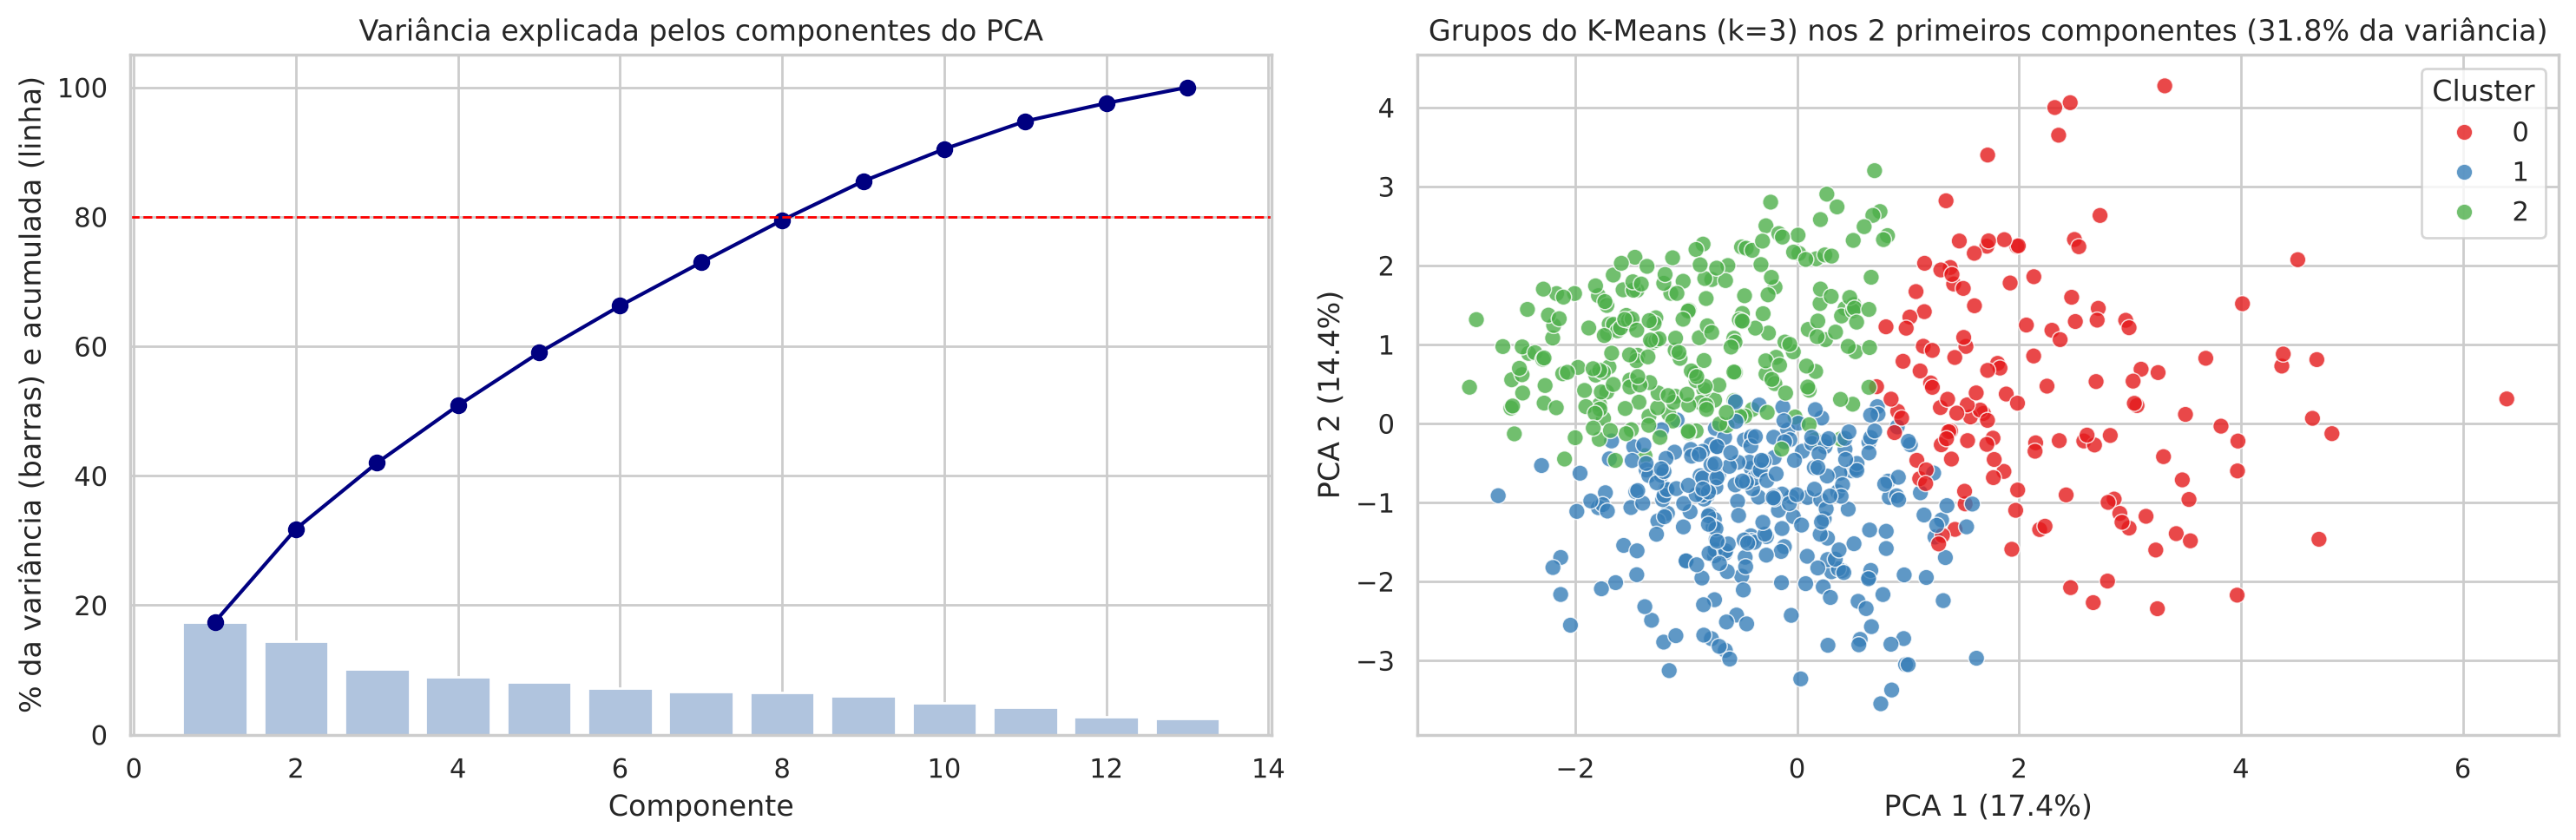

Componentes necessários para explicar 80% da variância: 9 de 13


In [30]:
K_ESCOLHIDO = 3
kmeans = KMeans(n_clusters=K_ESCOLHIDO, random_state=SEMENTE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_cluster)

pca_completo = PCA(random_state=SEMENTE).fit(X_cluster)
variancia_acumulada = np.cumsum(pca_completo.explained_variance_ratio_) * 100

pca = PCA(n_components=2, random_state=SEMENTE)
coords = pca.fit_transform(X_cluster)
df["PCA1"], df["PCA2"] = coords[:, 0], coords[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(1, len(variancia_acumulada) + 1), pca_completo.explained_variance_ratio_ * 100, color="lightsteelblue")
axes[0].plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker="o", color="navy")
axes[0].axhline(80, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Variância explicada pelos componentes do PCA")
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("% da variância (barras) e acumulada (linha)")
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="Set1", s=45, alpha=0.8, ax=axes[1])
axes[1].set_title(f"Grupos do K-Means (k={K_ESCOLHIDO}) nos 2 primeiros componentes ({var.sum():.1f}% da variância)")
axes[1].set_xlabel(f"PCA 1 ({var[0]:.1f}%)"); axes[1].set_ylabel(f"PCA 2 ({var[1]:.1f}%)")
plt.tight_layout(); plt.show()

print(f"Componentes necessários para explicar 80% da variância: {np.argmax(variancia_acumulada >= 80) + 1} de {len(colunas_cluster)}")

Os dois primeiros componentes explicam só 31,8% da variância (17,4% + 14,4%), e são necessários 9 dos 13 componentes para chegar a 80%. As variáveis trazem informações bem diferentes entre si, e o gráfico em 2D é uma simplificação; por isso os grupos aparecem com sobreposição, o que combina com a silhueta baixa.

Usamos o PCA para visualizar os grupos, e não para reduzir as variáveis dos modelos supervisionados. Com 29 a 32 variáveis e regularização, não há necessidade de comprimir os dados, e os componentes tornariam os resultados difíceis de explicar para a escola.

---

# Etapa 5: Avaliação

> **Enunciado da Especificação (Etapa 5):** *"5. Avaliação: métricas apropriadas ao problema, lidas na unidade do negócio ("erramos em média 2,5 anos", "encontramos 70% dos clientes que cancelam")."*

Agora cada modelo, já com os hiperparâmetros escolhidos na validação e treinado em todo o conjunto de treino, é aplicado **uma única vez** nos 130 alunos do teste.

## 5.1 Regressão - erro em pontos de nota

In [31]:
def avaliar_regressao(modelos, cenario):
    X_tr, X_te, y_tr, y_te = dados(cenario, "Nota_Final")
    linhas = []
    for nome, pipe in modelos.items():
        p_tr, p_te = pipe.predict(X_tr), pipe.predict(X_te)
        linhas.append({
            "Cenário": cenario, "Modelo": nome,
            "MAE treino": mean_absolute_error(y_tr, p_tr), "MAE teste": mean_absolute_error(y_te, p_te),
            "RMSE teste": np.sqrt(mean_squared_error(y_te, p_te)),
            "R² treino": r2_score(y_tr, p_tr), "R² teste": r2_score(y_te, p_te),
        })
    return pd.DataFrame(linhas).round(3)

teste_reg = pd.concat([avaliar_regressao(modelos_reg_a, "A"), avaliar_regressao(modelos_reg_b, "B")], ignore_index=True)
teste_reg[["Cenário", "Modelo", "MAE teste", "RMSE teste", "R² teste"]]

,Cenário,Modelo,MAE teste,RMSE teste,R² teste
0,A,Referência (média),2.600,3.562,-0.000
1,A,Regressão Linear,2.226,3.104,0.240
2,A,Ridge (L2),2.215,3.098,0.243
3,A,Lasso (L1),2.242,3.120,0.233
4,A,Random Forest,2.232,3.111,0.237
5,B,Referência (média),2.600,3.562,-0.000
6,B,Regressão Linear,0.850,1.465,0.831
7,B,Ridge (L2),0.855,1.491,0.825
8,B,Lasso (L1),0.825,1.470,0.830
9,B,Random Forest,0.929,1.505,0.821


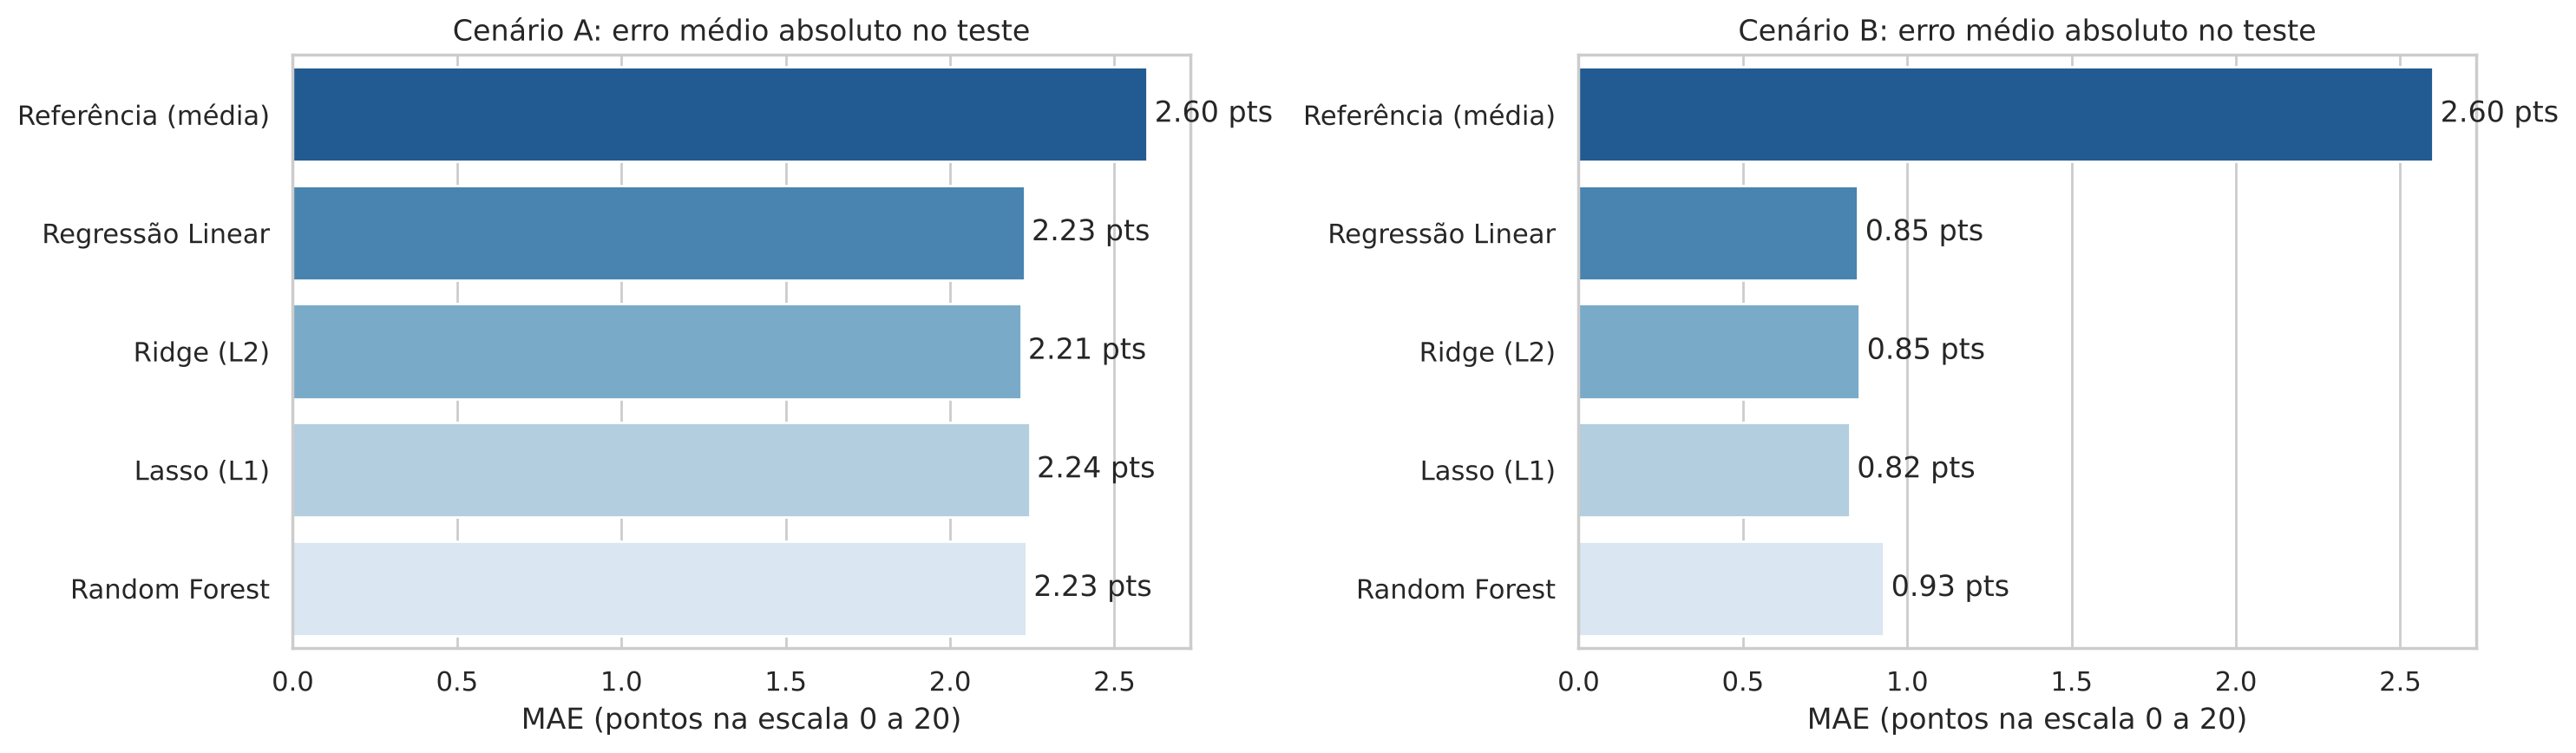

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, cen in zip(axes, ["A", "B"]):
    parte = teste_reg[teste_reg["Cenário"] == cen]
    sns.barplot(data=parte, x="MAE teste", y="Modelo", hue="Modelo", palette="Blues_r", legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f pts", padding=3)
    ax.set_title(f"Cenário {cen}: erro médio absoluto no teste"); ax.set_xlabel("MAE (pontos na escala 0 a 20)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

O MAE médio esconde onde o modelo erra mais. Abaixo, o erro do modelo escolhido em cada cenário separado por faixa da nota real.

In [33]:
faixas_nota = pd.cut(df.loc[idx_teste, "Nota_Final"], bins=[-1, 0, 9, 13, 20],
                     labels=["Nota 0", "1 a 9 (reprovado)", "10 a 13", "14 a 20"])

erros = {}
for cen, modelos, escolhido in [("A", modelos_reg_a, escolhido_reg_a), ("B", modelos_reg_b, escolhido_reg_b)]:
    _, X_te, _, y_te = dados(cen, "Nota_Final")
    erros[f"Cenário {cen} - {escolhido} (MAE)"] = (y_te - modelos[escolhido].predict(X_te)).abs()

tabela_faixas = pd.DataFrame(erros).groupby(faixas_nota, observed=True).mean().round(2)
tabela_faixas.insert(0, "Alunos no teste", faixas_nota.value_counts().reindex(tabela_faixas.index))
tabela_faixas

,Alunos no teste,Cenário A - Random Forest (MAE),Cenário B - Lasso (L1) (MAE)
Nota_Final,,,
Nota 0,4,10.55,4.44
1 a 9 (reprovado),16,2.75,1.29
10 a 13,68,1.42,0.59
14 a 20,42,2.56,0.69


Leitura na unidade do problema (pontos na escala de 0 a 20):

* **Referência:** prever a nota média do treino para todo mundo erra, em média, 2,60 pontos no teste.
* **Cenário A (início do ano):** o Random Forest, escolhido na validação, **erra em média 2,23 pontos** (R² = 0,24). Os outros modelos ficam entre 2,22 e 2,24. Ganhamos cerca de 0,37 ponto por aluno em relação à referência, uma melhora de 14%. É uma previsão grosseira: um aluno previsto com 11 pode terminar com 9 ou com 13.
* **Cenário B (fim do 2º período):** o Lasso **erra em média 0,82 ponto** (R² = 0,83), contra 2,60 da referência.

A tabela por faixa mostra onde estão os erros. No Cenário A, o erro é de 1,42 ponto para alunos com nota entre 10 e 13, mas sobe para 2,75 nos reprovados com nota de 1 a 9 e para 10,55 nos 4 alunos com nota zero. O modelo puxa as previsões para o meio da escala e não tem como antecipar quem vai abandonar. Mesmo no Cenário B, os alunos com nota zero têm erro de 4,44 pontos. Por isso, para decidir quem recebe apoio, a classificação (5.2) é mais útil que a nota prevista.

## 5.2 Classificação - quantos reprovados encontramos

In [34]:
def avaliar_classificacao(modelos, cenario):
    X_tr, X_te, y_tr, y_te = dados(cenario, "Risco_Reprovacao")
    linhas = []
    for nome, pipe in modelos.items():
        p_tr, p_te = pipe.predict(X_tr), pipe.predict(X_te)
        tn, fp, fn, tp = confusion_matrix(y_te, p_te).ravel()
        linhas.append({
            "Cenário": cenario, "Modelo": nome,
            "Reprovados encontrados": f"{tp} de {tp + fn}", "Falsos alarmes": fp,
            "Recall teste (%)": recall_score(y_te, p_te, zero_division=0) * 100,
            "Precisão teste (%)": precision_score(y_te, p_te, zero_division=0) * 100,
            "F1 treino": f1_score(y_tr, p_tr, zero_division=0), "F1 teste": f1_score(y_te, p_te, zero_division=0),
            "Recall treino (%)": recall_score(y_tr, p_tr, zero_division=0) * 100,
            "Acurácia teste (%)": accuracy_score(y_te, p_te) * 100,
        })
    return pd.DataFrame(linhas).round(3)

teste_clf = pd.concat([avaliar_classificacao(modelos_clf_a, "A"), avaliar_classificacao(modelos_clf_b, "B")], ignore_index=True)
teste_clf[["Cenário", "Modelo", "Reprovados encontrados", "Falsos alarmes", "Recall teste (%)",
           "Precisão teste (%)", "F1 teste", "Acurácia teste (%)"]].round(
    {"Recall teste (%)": 1, "Precisão teste (%)": 1, "F1 teste": 3, "Acurácia teste (%)": 1})

,Cenário,Modelo,Reprovados encontrados,Falsos alarmes,Recall teste (%),Precisão teste (%),F1 teste,Acurácia teste (%)
0,A,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
1,A,Logística sem balanceamento,2 de 20,4,10.0,33.3,0.154,83.1
2,A,Logística balanceada (L2),10 de 20,19,50.0,34.5,0.408,77.7
3,A,Random Forest balanceado,13 de 20,15,65.0,46.4,0.542,83.1
4,B,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
5,B,Logística sem balanceamento,16 de 20,6,80.0,72.7,0.762,92.3
6,B,Logística balanceada (L2),18 de 20,13,90.0,58.1,0.706,88.5
7,B,Random Forest balanceado,17 de 20,13,85.0,56.7,0.680,87.7


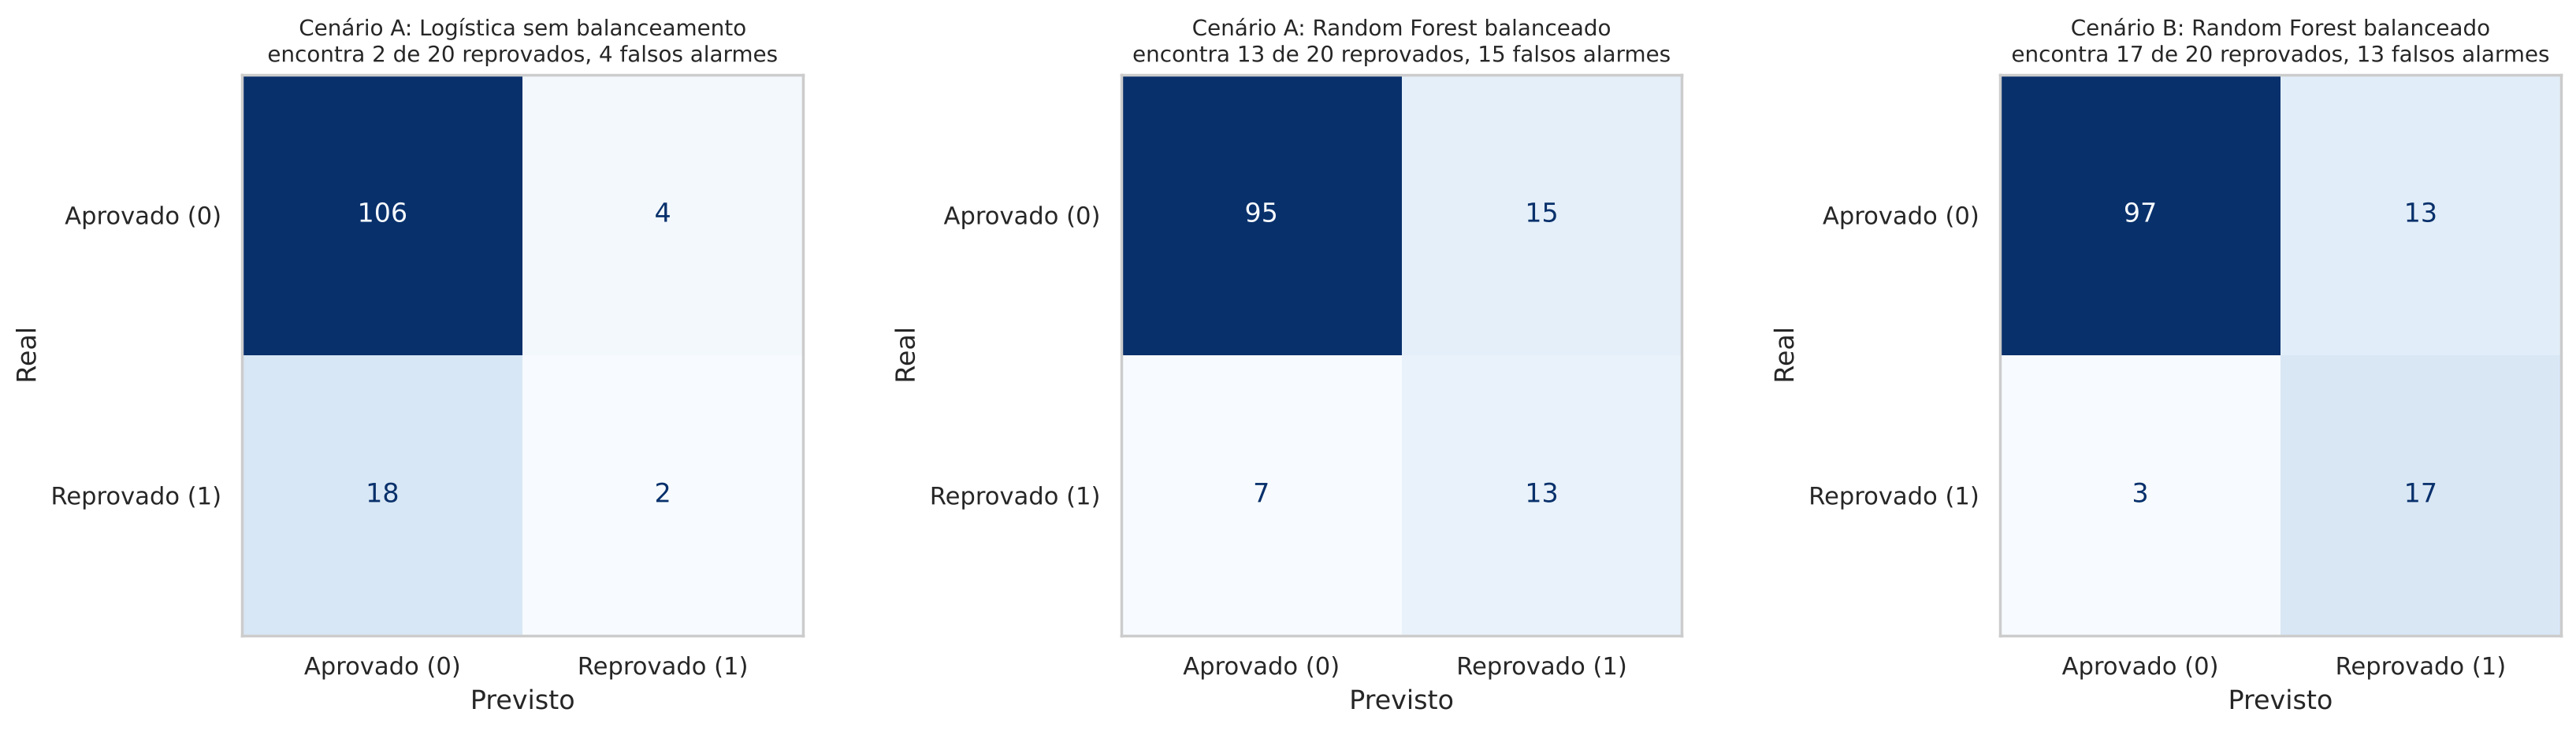

In [35]:
comparacoes = [("A", modelos_clf_a, "Logística sem balanceamento"),
               ("A", modelos_clf_a, escolhido_clf_a),
               ("B", modelos_clf_b, escolhido_clf_b)]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (cen, modelos, nome) in zip(axes, comparacoes):
    _, X_te, _, y_te = dados(cen, "Risco_Reprovacao")
    cm = confusion_matrix(y_te, modelos[nome].predict(X_te))
    ConfusionMatrixDisplay(cm, display_labels=["Aprovado (0)", "Reprovado (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Cenário {cen}: {nome}\nencontra {cm[1, 1]} de {cm[1].sum()} reprovados, {cm[0, 1]} falsos alarmes", fontsize=10)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.show()

No teste há 130 alunos, sendo 20 reprovados.

* **Referência:** 84,6% de acurácia, mas encontra 0 dos 20 reprovados. É o exemplo de por que a acurácia sozinha engana aqui.
* **Cenário A sem balanceamento:** a Logística encontra 2 de 20 reprovados (recall de 10%).
* **Cenário A, modelo escolhido (Random Forest balanceado):** **encontramos 65% dos alunos que iam reprovar (13 de 20) ainda no início do ano**, com 15 falsos alarmes. A precisão é de 46%: de cada 100 alunos indicados para reforço, cerca de 46 reprovariam. A Logística balanceada encontrou 10 de 20, com 19 falsos alarmes.
* **Cenário B, modelo escolhido (Random Forest balanceado):** encontra 17 de 20 reprovados (85%), com 13 falsos alarmes (precisão de 57%). No teste, a Logística balanceada encontrou 18 de 20, e a Logística sem balanceamento teve o maior F1 (0,762, com 16 de 20). Com só 20 reprovados no teste, a diferença entre esses modelos é de 1 ou 2 alunos. Não trocamos o modelo escolhido por causa do teste, porque isso seria usar o teste para escolher.

Para a escola, um falso alarme custa uma vaga de reforço para um aluno que passaria de qualquer forma; perder um reprovado significa não ajudar quem precisava. Por isso priorizamos o recall e aceitamos uma precisão menor.

## 5.3 Agrupamento - perfil de cada grupo

As notas não entraram no K-Means. Elas são usadas só agora, depois do agrupamento, para ver se os perfis encontrados têm relação com o desempenho.

In [36]:
perfil = df.groupby("Cluster").agg(
    Alunos=("Cluster", "size"),
    Idade=("Idade", "mean"),
    Escolaridade_da_Mae=("Escolaridade_da_Mae", "mean"),
    Tempo_de_Estudo=("Tempo_de_Estudo_Semanal", "mean"),
    Reprovacoes_Anteriores=("Reprovacoes_Anteriores", "mean"),
    Alcool_Fim_de_Semana=("Consumo_de_Alcool_no_Fim_de_Semana", "mean"),
    Saidas_com_Amigos=("Frequencia_de_Saidas_com_Amigos", "mean"),
    Faltas=("Numero_de_Faltas", "mean"),
    Nota_Final_media=("Nota_Final", "mean"),
)
perfil["% reprovados"] = df.groupby("Cluster")["Risco_Reprovacao"].mean() * 100
print(f"Silhueta com k={K_ESCOLHIDO}: {silhouette_score(X_cluster, df['Cluster']):.3f}")
perfil.round(2)

Silhueta com k=3: 0.102


,Alunos,Idade,Escolaridade_da_Mae,Tempo_de_Estudo,Reprovacoes_Anteriores,Alcool_Fim_de_Semana,Saidas_com_Amigos,Faltas,Nota_Final_media,% reprovados
Cluster,,,,,,,,,,
0,139,17.25,2.21,1.58,0.64,3.75,4.21,6.50,9.96,33.09
1,268,16.68,1.74,1.96,0.18,1.75,2.78,2.88,11.72,14.93
2,242,16.53,3.55,2.10,0.03,2.03,3.04,2.89,13.23,5.79


Mesmo sem as notas no agrupamento, os três perfis têm desempenhos bem diferentes. Os valores são médias dos códigos do dicionário (seção 1.3):

* **Grupo 0 (139 alunos), maior risco:** um pouco mais velhos (17,3 anos), mais reprovações anteriores (0,64 em média), menos estudo (1,58, entre "menos de 2 h" e "2 a 5 h"), saem mais com amigos (4,21 na escala de 1 a 5), bebem mais no fim de semana (3,75) e faltam mais (6,5 faltas). Nota final média de 9,96 e **33,1% de reprovação**.
* **Grupo 1 (268 alunos), intermediário:** menor escolaridade da mãe (1,74, perto de "do 5º ao 9º ano"), poucas faltas e baixo consumo de álcool. Nota média de 11,72 e **14,9% de reprovação**.
* **Grupo 2 (242 alunos), menor risco:** mães com maior escolaridade (3,55, entre secundário e superior), mais tempo de estudo e quase nenhuma reprovação anterior (0,03). Nota média de 13,23 e **5,8% de reprovação**.

A silhueta de 0,102 confirma que os grupos se sobrepõem, então um aluno do grupo 1 pode ser parecido com os do grupo 0. Mesmo assim, o perfil do grupo 0 dá à coordenação uma descrição simples de quem costuma precisar de mais atenção. Como as faltas usadas aqui são do ano inteiro, esse perfil é descritivo e não substitui o alerta do Cenário A.

---

# Etapa 6: Boas Práticas, Limitações e Conclusão

> **Enunciado da Especificação (Etapa 6):** *"6. Boas práticas, conforme a necessidade: evitar overfitting, validação adequada, regularização, tratamento de classes desbalanceadas e cuidado com vazamento de informações."*

## 6.1 Overfitting: comparação entre treino e teste

In [37]:
comparacao_reg = teste_reg[["Cenário", "Modelo", "MAE treino", "MAE teste", "R² treino", "R² teste"]].copy()
comparacao_reg["Diferença de MAE (teste - treino)"] = (comparacao_reg["MAE teste"] - comparacao_reg["MAE treino"]).round(2)
display(comparacao_reg.round(2))

comparacao_clf = teste_clf[["Cenário", "Modelo", "Recall treino (%)", "Recall teste (%)", "F1 treino", "F1 teste"]].copy()
comparacao_clf["Diferença de F1 (treino - teste)"] = (comparacao_clf["F1 treino"] - comparacao_clf["F1 teste"]).round(2)
display(comparacao_clf.round(2))

,Cenário,Modelo,MAE treino,MAE teste,R² treino,R² teste,Diferença de MAE (teste - treino)
0,A,Referência (média),2.36,2.60,0.00,-0.00,0.24
1,A,Regressão Linear,1.82,2.23,0.38,0.24,0.41
2,A,Ridge (L2),1.82,2.22,0.37,0.24,0.40
3,A,Lasso (L1),1.83,2.24,0.37,0.23,0.41
4,A,Random Forest,1.42,2.23,0.61,0.24,0.81
5,B,Referência (média),2.36,2.60,0.00,-0.00,0.24
6,B,Regressão Linear,0.76,0.85,0.87,0.83,0.09
7,B,Ridge (L2),0.76,0.86,0.86,0.82,0.10
8,B,Lasso (L1),0.76,0.82,0.84,0.83,0.06
9,B,Random Forest,0.72,0.93,0.86,0.82,0.21


,Cenário,Modelo,Recall treino (%),Recall teste (%),F1 treino,F1 teste,Diferença de F1 (treino - teste)
0,A,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
1,A,Logística sem balanceamento,36.25,10.0,0.48,0.15,0.33
2,A,Logística balanceada (L2),76.25,50.0,0.56,0.41,0.15
3,A,Random Forest balanceado,91.25,65.0,0.68,0.54,0.13
4,B,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
5,B,Logística sem balanceamento,77.50,80.0,0.83,0.76,0.07
6,B,Logística balanceada (L2),98.75,90.0,0.78,0.71,0.08
7,B,Random Forest balanceado,100.00,85.0,0.98,0.68,0.30


* **Regressão, Cenário A:** os modelos lineares pioram cerca de 0,4 ponto do treino para o teste. O Random Forest é o caso mais claro de sobreajuste: erra 1,42 ponto no treino e 2,23 no teste (R² cai de 0,61 para 0,24), e no fim não é melhor que a Ridge. Limitar a profundidade e o tamanho mínimo das folhas reduziu o problema, mas não o eliminou.
* **Regressão, Cenário B:** treino e teste ficam próximos nos modelos lineares (diferença de 0,06 a 0,10 ponto), sinal de boa generalização.
* **Classificação:** o Random Forest do Cenário B tem F1 de 0,98 no treino e 0,68 no teste, a maior queda da tabela. A Logística balanceada perde bem menos (0,78 para 0,71). No Cenário A, as quedas dos modelos balanceados ficam entre 0,13 e 0,15.
* Até a referência piora do treino para o teste (2,36 para 2,60 pontos). Parte da diferença vem do próprio conjunto de teste, que é pequeno e tem 4 dos 15 alunos com nota zero.

A validação cruzada com 5 partes foi o que nos protegeu de escolher um modelo pelo resultado do treino: ela já mostrava o Random Forest com erro de validação bem acima do erro de treino.

## 6.2 Vazamento de informação

Conferimos no código que nenhuma variável derivada da resposta entrou nos modelos e que o Cenário A não usa nada que só existe depois do início do ano.

In [38]:
for nome, (feats, _, _) in cenarios.items():
    assert not set(feats) & set(colunas_resposta), "variável de resposta entre as entradas"
    assert not set(feats) & {"Cluster", "PCA1", "PCA2"}, "resultado do agrupamento entre as entradas"
assert not set(features_a) & set(so_no_cenario_b)
assert len(set(idx_treino) & set(idx_teste)) == 0
print("Nenhuma variável de resposta nas entradas dos dois cenários.")
print("Cenário A sem notas parciais e sem faltas do ano.")
print("Treino e teste sem alunos em comum.")

Nenhuma variável de resposta nas entradas dos dois cenários.
Cenário A sem notas parciais e sem faltas do ano.
Treino e teste sem alunos em comum.


Resumo do que fizemos para evitar vazamento:

* **Divisão antes de qualquer ajuste:** o `train_test_split` foi feito na Etapa 3, antes de padronizar ou codificar. O `StandardScaler` e o `OneHotEncoder` estão dentro do `Pipeline`, então aprendem só com o treino (e, na validação cruzada, só com as partes de treino de cada rodada).
* **Teste usado uma vez:** hiperparâmetros e modelo escolhido saíram da validação cruzada no treino. O teste só foi usado na Etapa 5.
* **Variáveis que contêm a resposta:** `Situacao_Final` e `Risco_Reprovacao` são calculadas a partir da `Nota_Final` e ficaram fora das entradas. O resultado do K-Means (`Cluster`), que foi calculado com a base toda, também não entrou nos modelos supervisionados.
* **Disponibilidade no tempo:** separamos os cenários A e B. A diferença de desempenho entre eles (seção 5) mostra o tamanho do efeito das notas parciais. Se tivéssemos usado as notas no "alerta do início do ano", o modelo pareceria ótimo, mas seria impossível usá-lo na prática.

## 6.3 Regularização

In [39]:
linhas = []
for cen, modelos in [("A", modelos_reg_a), ("B", modelos_reg_b)]:
    coef_linear = modelos["Regressão Linear"].named_steps["modelo"].coef_
    for nome in ["Ridge (L2)", "Lasso (L1)"]:
        modelo = modelos[nome].named_steps["modelo"]
        linhas.append({"Cenário": cen, "Modelo": nome, "alpha": modelo.alpha,
                       "Coeficientes": len(modelo.coef_),
                       "Coeficientes zerados": int((np.abs(modelo.coef_) < 1e-8).sum()),
                       "Soma |coef| (linear sem regularização)": round(np.abs(coef_linear).sum(), 2),
                       "Soma |coef| (regularizado)": round(np.abs(modelo.coef_).sum(), 2)})
pd.DataFrame(linhas)

,Cenário,Modelo,alpha,Coeficientes,Coeficientes zerados,Soma |coef| (linear sem regularização),Soma |coef| (regularizado)
0,A,Ridge (L2),30.00,42,0,13.47,9.69
1,A,Lasso (L1),0.03,42,17,13.47,8.08
2,B,Ridge (L2),30.00,45,0,7.35,6.02
3,B,Lasso (L1),0.30,45,43,7.35,2.63


* A validação escolheu `alpha=30` para a Ridge nos dois cenários. No Cenário A, a soma dos coeficientes (em módulo) cai de 13,47 na regressão linear para 9,69: o modelo depende menos de cada variável isolada, o que ajuda com as variáveis correlacionadas vistas na EDA.
* O Lasso no Cenário A zerou 17 dos 42 coeficientes, entre eles todas as categorias de ocupação do pai e da mãe, o tamanho da família, a situação dos pais e o tempo de deslocamento. Para prever a nota, essas variáveis não acrescentam informação depois que as outras já estão no modelo.
* No Cenário B, o Lasso zerou 43 dos 45 coeficientes e ficou só com `Nota_1o_Periodo` e `Nota_2o_Periodo`, com quase todo o peso na nota do 2º período. Com as notas parciais disponíveis, o resto das variáveis praticamente não muda a previsão, e esse modelo mais simples foi justamente o de menor erro na validação.
* Na classificação, a Logística balanceada do Cenário A ficou com `C=0,01`, uma regularização forte, e o Random Forest teve profundidade e folhas limitadas.

## 6.4 Classes desbalanceadas e variáveis que mais pesam no alerta do início do ano

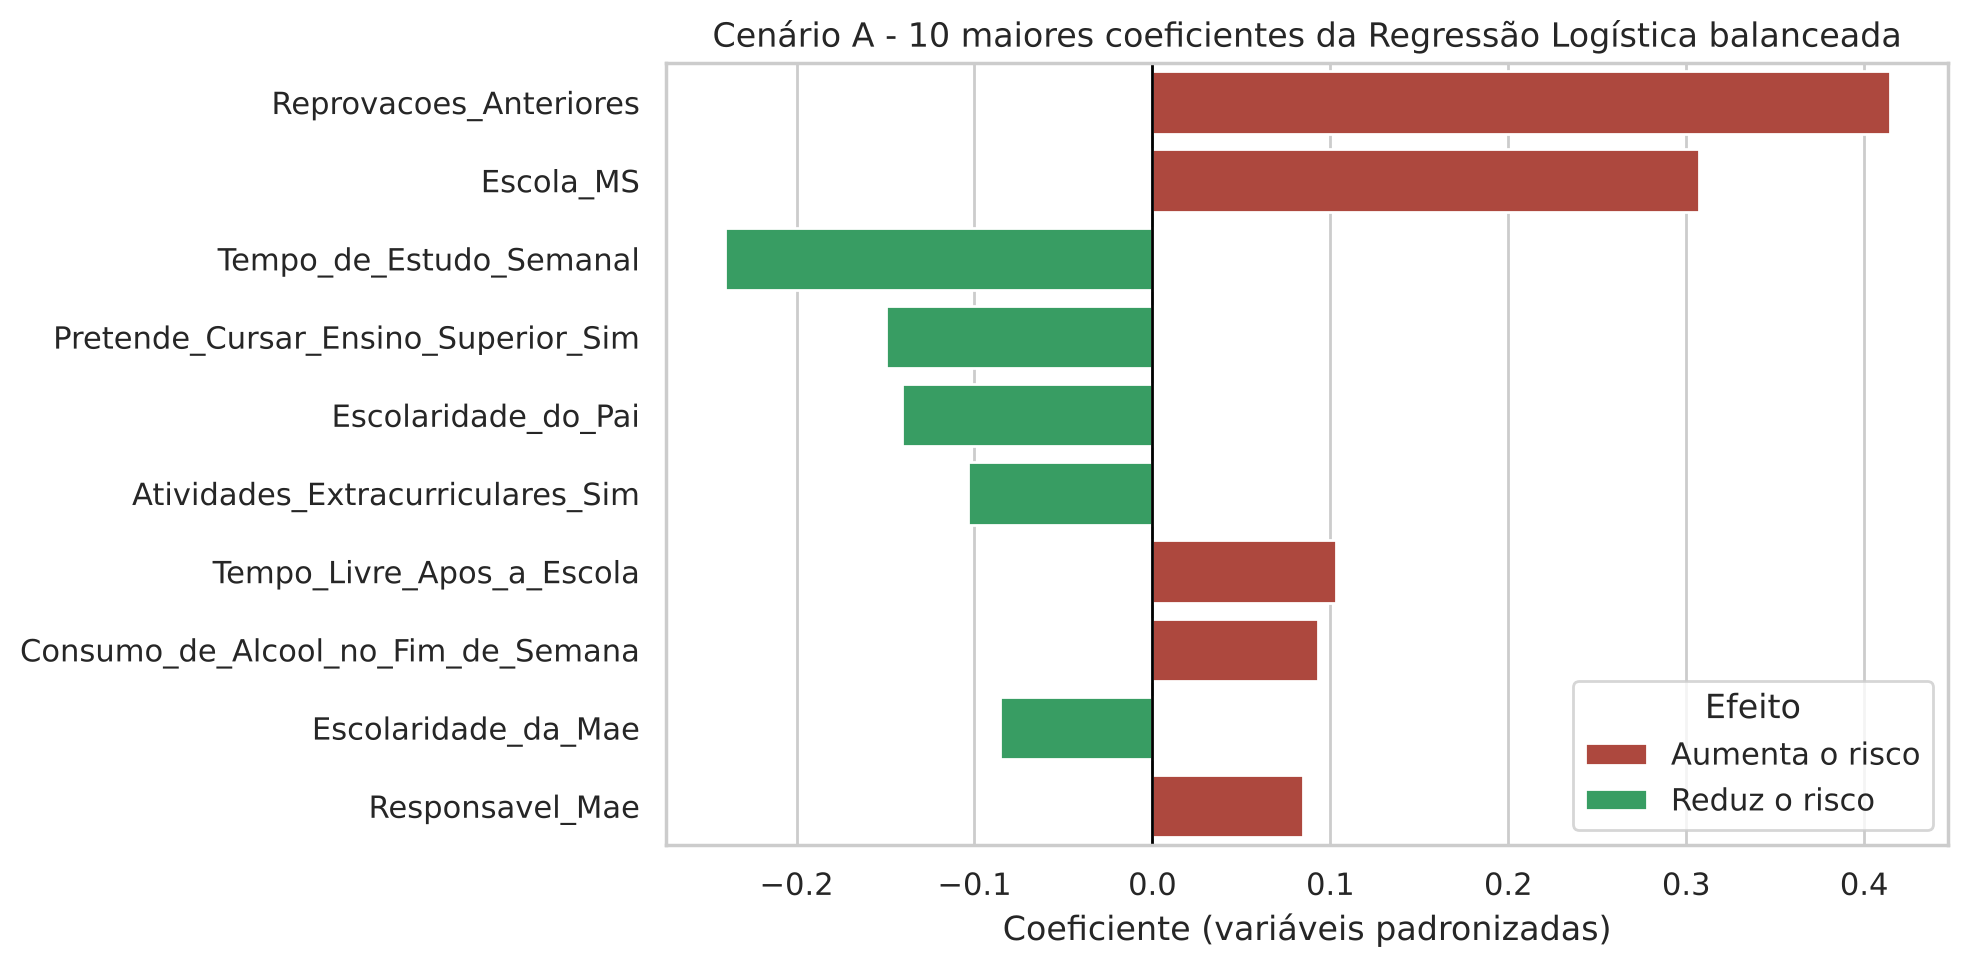

In [40]:
pipe_alerta = modelos_clf_a["Logística balanceada (L2)"]
nomes = [n.replace("num__", "").replace("cat__", "") for n in pipe_alerta.named_steps["prep"].get_feature_names_out()]
coeficientes = pd.DataFrame({"Variável": nomes, "Coeficiente": pipe_alerta.named_steps["modelo"].coef_[0]})
coeficientes["Efeito"] = np.where(coeficientes["Coeficiente"] > 0, "Aumenta o risco", "Reduz o risco")
top = coeficientes.reindex(coeficientes["Coeficiente"].abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top, x="Coeficiente", y="Variável", hue="Efeito",
            palette={"Aumenta o risco": "#c0392b", "Reduz o risco": "#27ae60"}, dodge=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Cenário A - 10 maiores coeficientes da Regressão Logística balanceada")
plt.xlabel("Coeficiente (variáveis padronizadas)"); plt.ylabel("")
plt.tight_layout(); plt.show()

**Efeito do balanceamento:** no teste do Cenário A, a Logística sem balanceamento encontrou 2 dos 20 reprovados; com `class_weight="balanced"` passou para 10 de 20, e o Random Forest balanceado chegou a 13 de 20. No Cenário B, o recall da Logística foi de 80% para 90%. O custo é uma precisão menor (mais falsos alarmes), aceitável para uma ação de apoio. Não usamos SMOTE nem outra reamostragem: o ajuste de pesos já resolveu o problema sem criar alunos artificiais.

**Variáveis mais importantes:** usamos os coeficientes da Logística balanceada para explicar o alerta do início do ano, porque eles mostram a direção do efeito (o Random Forest teve desempenho parecido, mas não mostra se a variável aumenta ou reduz o risco). Como as variáveis numéricas foram padronizadas, os tamanhos podem ser comparados. O que mais aumenta o risco é o número de reprovações anteriores, seguido de estudar na escola MS. O que mais reduz é o tempo de estudo semanal, depois querer cursar o ensino superior, a escolaridade do pai, fazer atividades extracurriculares e a escolaridade da mãe.

Esses coeficientes mostram associação, não causa. Estudar na escola MS não causa reprovação; a escola provavelmente reúne outros fatores que a base não mede.

## 6.5 Limitações

* **Generalização:** são 649 alunos de duas escolas portuguesas, numa única disciplina (Língua Portuguesa) e num único ano de coleta. Para usar em outras escolas, inclusive brasileiras, o modelo teria de ser treinado de novo com dados locais.
* **Tamanho do teste:** o teste tem só 20 reprovados. Um aluno a mais ou a menos muda o recall em 5 pontos percentuais, então os números devem ser lidos como aproximados.
* **Faltas no Cenário B:** usamos o total de faltas do ano, que ainda não estaria completo no fim do 2º período. O ideal seria ter as faltas acumuladas até aquele momento; com o dado disponível, o Cenário B pode estar um pouco otimista.
* **Notas zero:** os 15 alunos com nota final zero e nenhuma falta parecem ser abandonos ou ausência na avaliação, mas a base não confirma. Eles concentram os maiores erros da regressão.
* **Dados de questionário:** tempo de estudo, consumo de álcool, saúde e relação familiar são respostas dos próprios alunos e podem ter viés (por exemplo, subestimar o consumo de álcool).
* **Desempenho do Cenário A:** sem notas, o modelo explica cerca de 24% da variação da nota e menos da metade dos alunos apontados de fato reprovaria. Ele serve para priorizar quem recebe atenção, não para afirmar que um aluno vai reprovar.
* **Uso responsável:** variáveis como escola, sexo e situação familiar não devem servir para rotular alunos. A saída do modelo deve virar oferta de apoio, nunca punição ou exclusão.

## 6.6 Conclusão

O objetivo era apoiar a escola na decisão de quem deve receber reforço. Os principais resultados foram:

* **No início do ano**, sem nenhuma nota, o modelo encontrou 65% dos alunos que reprovariam (13 de 20 no teste), contra 0% da referência. A previsão da nota é menos útil nesse momento: erra em média 2,23 pontos, só 0,37 ponto a menos que prever a média.
* **No fim do 2º período**, com as notas parciais, o modelo encontrou 85% dos reprovados (17 de 20), e a nota final foi prevista com erro médio de 0,82 ponto. Quase toda a informação vem da nota do 2º período, então ela já funciona como um bom sinal de alerta.
* **Os fatores mais ligados ao risco** são reprovações anteriores, pouco tempo de estudo, a escola e não ter planos de cursar o ensino superior. O agrupamento chegou a um perfil parecido sem usar as notas (grupo 0, com 33% de reprovação).

Na prática, sugerimos usar o modelo do Cenário A para montar uma primeira lista de acompanhamento no começo do ano e revisar essa lista com o Cenário B depois do 2º período, lembrando que a lista indica prioridade de apoio e não uma previsão certa sobre cada aluno.